**Bitácora · Day 3 PrefixSpan (letrozole)**

- **v1** `Day3_prefixspan_v1`  
  PrefixSpan on group tags, visits kept; v1 NMF components. *Files:* `patterns_letrozole.json`, `nmf_k8_letrozole.npz`
- **v2** `Day3_prefixspan_v2`  
  Motifs per visit-pruned NMF component; Table 1, stability (2b), matched plots. *Files:* `nmf_k8_letrozole_v2.npz`
- **v3 hybrid** `Day3_prefixspan_v3_hybrid` (2026-10-06)  
  v2 + deterministic ties, held-out pass rate, same-day flag, Excel export. *Files:* `nmf_k8_letrozole_v2.npz`, `Day3_v3_hybrid_top3_patterns_table.xlsx`
- **v3 concept** `Day3_prefixspan_v3_concept` (2026-10-07) ← **this notebook**  
  Hybrid on concept-level tokens; k=7 bundles named directly (v2 matching only for other k). *Files:* `nmf_k8_letrozole_v3.npz`, `Day3_v3_concept_final_table_letrozole_k{K}.xlsx`, `token_map_letrozole_concept.csv`

# Day 3 · v3 hybrid · concept-level tokens — sequence motifs inside the visit-pruned NMF components (letrozole)

**Today's goal:** mine ordered motifs *within each of the NMF components* from `Day1_nmf_v3`,
on event streams with every visit event removed (care-driven bias). Same PrefixSpan as v1; what
changes is the input (no visit tokens) and the groups (v2 components, not v1's).

Why: in v1 the most common tokens were pharmacy / office visits, so most motifs were chains like
`pharmacy__visit -> letrozole -> pharmacy__visit`. Day 1 v2 told us *which codes co-occur* once
visits are gone; Day 3 v2 asks *in what order*, and whether the fertility vs oncology split of
letrozole shows up as different pathways rather than different care settings.

> **v3 hybrid = this v2 notebook + three additions; v2 itself is untouched.**
> 1. **Deterministic ties** — PrefixSpan counts and every sort now break ties on the pattern, so two runs give the same motifs (v2 depended on Python's hash order).
> 2. **Section 2c · held-out pass rate** — for each motif, the share of 20 random 50/50 splits × 2 directions (40 runs) in which it still passes on the half it was *not* found on; also family-level (near-duplicate motifs vote as one).
> 3. **Same-day flag** — support re-counted with a strictly-later-date rule. A motif whose support collapses is a same-day bundle (co-occurrence), not an evidenced order.
> A final cell writes the top-3 patterns table to Excel.

> **Day 3 v3 concept = the v3 hybrid on concept-level tokens; the group-token hybrid is untouched.**
> `tag_events(..., token_level="concept")`: every event is its own token (`<name20>__<class>__<concept_id>`); the curated group lives in
> `events.group`. The NMF cache is `nmf_k8_letrozole_v3.npz` (written by `Day1_nmf_v3`, or fitted here if missing). At k=7 `COMP` is set
> directly from the Day 1 v3 top tokens (no v2 matching); for any other `K` it is seeded by matching to the v2 components (overlap table printed). The trajectory
> graph relabels tokens to their group (it is about curated clinical steps). Expect same-day variants of one test (e.g. three ECG codes)
> to appear as separate tokens; the hybrid's same-day flag marks those motifs as bundles.

In [22]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 150); pd.set_option('display.max_columns', 40)
import ethos_omop as eo

OUT_DIR = "../../inputs/letrozole_cohort/"   # matches Day 1's extract_cohort() output dir
DOMAINS = ['Visit', 'Condition', 'Drug', 'Procedure', 'Measurement']   # Visit stays in the load so we can show before vs after

if not os.path.isdir(OUT_DIR):
    raise FileNotFoundError(
        f"{OUT_DIR}/ not found. Run Day 1's eo.extract_cohort(...) (or "
        f"eo.extract_omop(...) with OUT_DIR='omop_extract') first, or "
        f"python make_demo_extract.py for a synthetic stand-in.")

concept  = eo.load_concept(OUT_DIR)
codesets = eo.build_codesets(concept, verbose=False)
raw      = eo.load_events(OUT_DIR, domains=DOMAINS)
person   = eo.load_person(OUT_DIR)
truth    = eo.load_truth(OUT_DIR)                   # None against real data

# v2: drop every visit event BEFORE tagging (same rule as Day1_nmf_v2): a row is a visit if its
# domain OR vocabulary is "visit".
is_visit = (raw['domain'].astype(str).str.lower().eq('visit')
            | raw['vocabulary_id'].astype(str).str.lower().eq('visit'))
visit_ids = set(raw.loc[is_visit, 'concept_id'])
events   = eo.tag_events(raw[~is_visit].reset_index(drop=True), codesets, token_level="concept", multi_group=True)

tbl = (pd.DataFrame({'before': raw['domain'].value_counts(), 'after': events['domain'].value_counts()})
         .fillna(0).astype(int))
tbl.loc['TOTAL'] = [len(raw), len(events)]
tbl['removed_%'] = ((1 - tbl['after'] / tbl['before']) * 100).round(1)
print("events per domain, BEFORE vs AFTER visit pruning")
print(tbl.to_string())
print(f"\npatients: {raw.person_id.nunique():,} -> {events.person_id.nunique():,}")
print("curated codeset tags on visit concepts (now absent):",
      sorted(t for t, ids in codesets.items() if set(ids) & visit_ids) or "none")
if not eo.group_mask(events, 'letrozole').any():
    print("WARNING: the cohort anchor `letrozole` has no events after pruning")
del raw                                              # free memory

print(f"\nevents {events.shape}   patients {events.person_id.nunique()}")
print(f"codeset coverage: {events.in_codeset.mean():.1%} of events carry a clinical tag")
print(f"truth labels: {'present (DEMO extract)' if truth is not None else 'ABSENT (real data)'}")
events.head(6)

events per domain, BEFORE vs AFTER visit pruning
              before    after  removed_%
domain                                  
Condition     458033   458033        0.0
Drug          523552   523552        0.0
Measurement   339167   339167        0.0
Procedure     390455   390455        0.0
Visit         709880        0      100.0
TOTAL        2421087  1711207       29.3

patients: 5,238 -> 5,238
curated codeset tags on visit concepts (now absent): none

events (1711207, 13)   patients 5238
codeset coverage: 8.9% of events carry a clinical tag
truth labels: ABSENT (real data)


,person_id,concept_id,event_date,domain,vocabulary_id,concept_code,concept_name,concept_class_id,token,group,groups,in_codeset,tag
0,1949,40223740,2019-07-01,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740
1,1949,40223740,2019-07-01,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740
2,1949,40223740,2019-09-25,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740
3,1949,40223740,2019-09-25,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740
4,1949,40223740,2019-12-27,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740
5,1949,40223740,2019-12-27,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740


## Mini Table 1 · letrozole cohort by confirmed breast-cancer diagnosis

**Confirmed breast cancer** = a patient with *any* condition row matching **ICD-9 174.x**, **ICD-10 C50.x** or
**SNOMED concept 4162253** (primary malignant neoplasm of breast). Everyone else is "no breast cancer dx".
The extract keeps standard concepts only, so ICD codes are not in `concept.csv`; they are read from the raw
`condition_source_value` column, which `load_events()` drops. The `breast_cancer` tag used elsewhere in this notebook
is the narrower, name-matched codeset, so the two counts differ (see the "meets" rows).

In [23]:
cond = pd.read_csv(os.path.join(OUT_DIR, 'master_condition_occurrence.csv'),
                   usecols=['person_id', 'condition_concept_id', 'condition_source_value', 'condition_start_date'],
                   dtype={'condition_source_value': str}, parse_dates=['condition_start_date'])
src  = cond.condition_source_value.fillna('').str.upper().str.replace('.', '', regex=False)   # 'C50.911' -> 'C50911'
crit = {'ICD-9 174.x':     src.str.startswith('174'),
        'ICD-10 C50.x':    src.str.startswith('C50'),
        'SNOMED 4162253':  cond.condition_concept_id.eq(4162253)}

cohort_ids = set(events.person_id)
case_mask  = np.logical_or.reduce(list(crit.values()))
case_ids   = set(cond.person_id[case_mask]) & cohort_ids
groups = {'Overall': cohort_ids,
          'No breast cancer dx': cohort_ids - case_ids,
          'Confirmed breast cancer dx': case_ids}

lz        = eo.index_dates(events, 'letrozole').set_index('person_id')['index_date']
age_yrs   = (lz - person.set_index('person_id')['birth_date'].reindex(lz.index)).dt.days / 365.25
female    = set(person.loc[person.gender.astype(str).str.upper().eq('FEMALE'), 'person_id'])
first_dx  = cond[case_mask].groupby('person_id').condition_start_date.min()       # first confirmed dx per patient
crit_ids  = {k: set(cond.person_id[m]) & cohort_ids for k, m in crit.items()}

# diagnosis-related rows: curated codesets whose events are conditions
ev_c      = events[events.group.notna()]
tag_dom   = ev_c.assign(g=ev_c.groups.astype(str).str.split('|')).explode('g').groupby('g').domain.agg(lambda s: s.mode().iat[0])
DX_TAGS   = sorted(tag_dom.index[tag_dom == 'Condition'])
has       = {t: set(ev_c.loc[eo.group_mask(ev_c, t), 'person_id']) for t in DX_TAGS}

def describe(name, ids):
    n   = len(ids)
    npc = lambda k: f"{k} ({k / n:.1%})" if n else "0"
    a   = age_yrs.reindex(list(ids))
    row = {'N (% of cohort)': f"{n} ({n / len(cohort_ids):.1%})",
           'Age at first letrozole, mean (SD)': f"{a.mean():.1f} ({a.std():.1f})" if n else '-',
           'Female, n (%)': npc(len(ids & female))}
    for k, s in crit_ids.items():
        row[f'Meets {k}, n (%)'] = npc(len(ids & s))
    before = [first_dx.get(p) is not None and first_dx[p] < lz[p] for p in ids]
    row['Dx recorded before first letrozole, n (%)'] = npc(sum(before)) if name == 'Confirmed breast cancer dx' else '-'
    for t in DX_TAGS:
        row[f'{t}, n (%)'] = npc(len(ids & has[t]))
    return row

table1 = pd.DataFrame({name: describe(name, ids) for name, ids in groups.items()})
display(table1)
print("curated diagnosis codesets shown:", DX_TAGS)

,Overall,No breast cancer dx,Confirmed breast cancer dx
N (% of cohort),5238 (100.0%),5168 (98.7%),70 (1.3%)
"Age at first letrozole, mean (SD)",35.2 (6.9),34.9 (6.6),51.8 (8.2)
"Female, n (%)",5238 (100.0%),5168 (100.0%),70 (100.0%)
"Meets ICD-9 174.x, n (%)",0 (0.0%),0 (0.0%),0 (0.0%)
"Meets ICD-10 C50.x, n (%)",70 (1.3%),0 (0.0%),70 (100.0%)
"Meets SNOMED 4162253, n (%)",49 (0.9%),0 (0.0%),49 (70.0%)
"Dx recorded before first letrozole, n (%)",-,-,43 (61.4%)
"breast_cancer, n (%)",49 (0.9%),0 (0.0%),49 (70.0%)
"dcis, n (%)",20 (0.4%),5 (0.1%),15 (21.4%)
"infertility, n (%)",1995 (38.1%),1993 (38.6%),2 (2.9%)


curated diagnosis codesets shown: ['breast_cancer', 'dcis', 'infertility', 'menopause_status', 'pcos', 'pregnancy_outcome', 't2dm']


In [24]:
seqs = eo.sequences(events, col='tag', dedup_same_day=True, collapse_repeats=True)
pids = sorted(seqs)
db   = [seqs[p] for p in pids]

print("example timeline:")
print(' -> '.join(db[1][:12]))
print("\nmedian sequence length:", int(np.median([len(s) for s in db])))

example timeline:
7_ethinyl_estradiol___branded_pack__19129357 -> nitrofurantoin_macro__clinical_drug__46234346 -> 7_ethinyl_estradiol___branded_pack__19129357 -> hydrocortisone_0025___clinical_drug__19002273 -> 7_ethinyl_estradiol___branded_pack__19129357 -> omeprazole_20_mg_del__clinical_drug__19019418 -> 7_ethinyl_estradiol___branded_pack__19129357 -> sarscov2_covid19_vac__clinical_drug__37003436 -> oseltamivir_75_mg_or__clinical_drug__1799141 -> letrozole_25_mg_oral__clinical_drug__19022830 -> venipuncture_for_blo__procedure__4102442 -> drug_tests_presumpti__cpt4__42628602

median sequence length: 176


### The preprocessing decisions, restated

The first two live in `eo.sequences()` and both are arbitrary:

1. **Same-day ties.** Claims carry a date, not a timestamp, so `DOMAIN_ORDER` breaks ties.
   Visit, condition, procedure, measurement, drug, observation.
2. **Refill collapsing.** Consecutive repeats of the same tag become one token, otherwise
   every pattern is `metformin -> metformin -> metformin`. Chronicity is real signal, so
   capture it as a separate feature — fill count, days supply — not as sequence position.
3. **Visits are not in the sequence at all (v2).** In v1 pharmacy visits were the most common
   tokens (`pharmacy__visit__38004338`) and made every motif list a chain of pharmacy / office
   visits. Dropping them removes that care-setting bias. Visit-borne signal is invisible here by
   construction (Day 1 v2 found no curated tag sitting on a visit concept, so no codeset tag is lost).

## 1 · PrefixSpan, implemented

In [25]:
import collections

def prefixspan(db, min_sup, max_len=4):
    """Minimal PrefixSpan over single-item sequences.

    db      : list of lists of tokens
    min_sup : minimum number of sequences containing the pattern
    returns : DataFrame of (pattern, support, support_pct)
    """
    n, results = len(db), []

    def scan(projected, prefix):
        counts = collections.Counter()
        for seq in projected:
            for item in sorted(set(seq)):                   # count each sequence once
                counts[item] += 1
        for item, c in counts.items():
            if c < min_sup:
                continue
            new_prefix = prefix + [item]
            results.append((tuple(new_prefix), c))
            if len(new_prefix) >= max_len:
                continue
            # project: keep the suffix after the FIRST occurrence of item
            nxt = [seq[seq.index(item) + 1:] for seq in projected if item in seq]
            if nxt:
                scan(nxt, new_prefix)

    scan([list(s) for s in db], [])
    return (pd.DataFrame(results, columns=['pattern', 'support'])
              .assign(support_pct=lambda d: (d.support / n * 100).round(1)))

## 2 · Discriminative mining — motifs per NMF component

Raw support finds whatever is common, which is mostly ambient care. What you want is patterns
common **inside** a group and rare **outside** it. Here the groups are the **NMF components of
`Day1_nmf_v3`** (k=7 on concept-level tokens, visits pruned).

What the v2 components look like (top codes and the Day 1 v2 fertility / oncology cross-tab):

- **Fertility, four bundles:** treatment c2 (gonadotropins, GnRH agonist, ART), carrier screening c4,
  prenatal labs c7 (ABO / Rh), pregnancy outcome c0.
- **Oncology, one bundle: c5.** Its top codes are peri-operative (ondansetron / ketorolac injectables,
  fentanyl, propofol), but it holds 62% of the breast-cancer-only patients. It is small, so read it as a lower bound.
- **Background, c1, c3, c6:** acute-infection pharmacy (antibiotics, steroids, NSAIDs), preventive
  labs (lipids, HbA1c, TSH, vitamin D), therapeutic / manual procedures (PT, chiropractic).
  Without visit tokens c1 is no longer "pharmacy visits" but the drugs themselves.

Day 3 asks what order those codes come in, per component. The draft triage (needs underwriter
review) is printed next to each component below.

In [26]:
from scipy import sparse as sp
from sklearn.decomposition import NMF

# Rebuild Day1_nmf_v3's k=K NMF exactly (same prevalence floor, same anchor drop, same NMF_KW; nndsvd
# init is deterministic), so component numbers match its loadings tables. Day1_nmf_v2 writes the
# cache file below; if it is missing or stale (different extract / floor) this cell fits and saves it.
n_pat      = events.person_id.nunique()
N_TRAIN    = min(20_000, int(0.6 * n_pat))
MIN_PAT    = int(np.ceil(5 * n_pat / N_TRAIN))
prev_pat   = events.groupby('tag').person_id.nunique()
KEEP_TAGS  = prev_pat.index[prev_pat >= MIN_PAT]
nmf_cols   = KEEP_TAGS[~KEEP_TAGS.isin(events.loc[eo.group_mask(events, 'letrozole'), 'tag'])]                 # cohort anchor, 100% prevalence
K          = 7                                           # NMF components: the stable k from Day1_nmf_v3 (v2 used 8)
CACHE      = f"nmf_k{K}_letrozole_v3.npz"                # same file Day1_nmf_v3 writes (v1's file is untouched)

z = np.load(CACHE) if os.path.exists(CACHE) else None
if z is not None and (set(z['cols']) != set(nmf_cols)
                      or set(z['pids']) != set(events.person_id.unique())):
    z = None                                             # stale: different extract / floor

if z is not None:
    H   = pd.DataFrame(z['H'], columns=z['cols'])
    lab = pd.Series(z['labels'], index=z['pids'])
    print(f"NMF k={K} loaded from {CACHE}")
else:
    Xb   = eo.bag_of_codes(events[events.tag.isin(KEEP_TAGS)], min_count=1)
    Xs   = sp.csr_matrix(Xb[nmf_cols].to_numpy()).astype(float)
    nmf  = NMF(n_components=K, init='nndsvd', random_state=0, max_iter=2000, tol=1e-4).fit(Xs)
    H    = pd.DataFrame(nmf.components_, columns=nmf_cols)
    lab  = pd.Series(nmf.transform(Xs).argmax(1), index=Xb.index)
    np.savez(CACHE, H=H.to_numpy(), cols=np.array(H.columns, dtype=str), pids=lab.index.to_numpy(),
             labels=lab.to_numpy())
    print(f"NMF k={K} fitted, cached to {CACHE}")

comp = lab.reindex(pids).fillna(-1).astype(int).to_numpy()   # aligned with db / pids

# Names read off the Day1_nmf_v2 top-codes and cross-tab; the assert fails loudly if numbering drifted.
# DRAFT triage (carried over from v1) -- needs underwriter review.
FERT, ONCO, BG = 'fertility', 'oncology', 'background'
MANUAL, EXPLAINED, UNCLEAR = ('manual UW review (stage, treatment status, adjuvant letrozole)',
                              'routine (letrozole explained by fertility)',
                              'routine, indication unclear (use other evidence)')
COMP_V2 = {0: ('pregnancy_outcome',   'pregnancy outcome',                                         FERT, EXPLAINED),
        1: ('amoxicillin_875',     'acute-infection pharmacy (antibiotics, steroids, NSAIDs)',    BG,   UNCLEAR),
        2: ('gonadotropin_drug',   'fertility treatment (high-intensity: ART, gonadotropins)',    FERT, EXPLAINED),
        3: ('lipid_panel',         'preventive labs (+ milder PCOS / ovarian-reserve workup)',    BG,   UNCLEAR),
        4: ('cftr',                'preconception carrier screening',                             FERT, EXPLAINED),
        5: ('ondansetron_injectio','peri-operative / oncology (breast_cancer loads here)',        ONCO, MANUAL),
        6: ('therapeutic_procedur','therapeutic / manual procedures (PT, chiropractic)',          BG,   UNCLEAR),
        7: ('abo_typing',          'prenatal labs (ABO / Rh)',                                    FERT, EXPLAINED)}
# (Skipped when K == 7: the names are set directly below. For any other K:) the NMF is refit on concept-level tokens, so component numbers
# and top codes are NOT assumed. Each v3 component is matched
# to a group-level (v2) component by patient overlap (Hungarian on the contingency table); the v2 name / group / triage are carried
# over and the agreement is printed. Edit COMP by hand if a match looks wrong; with no v2 cache the components are auto-named.
from scipy.optimize import linear_sum_assignment
V2_CACHE, V2_OF, MERGED, COMP = "nmf_k8_letrozole_v2.npz", {}, {}, {}
if K == 7:                                      # the v3 run loads k=7: names are set directly below, no comparison with v2
    print("k=7: components named directly from the Day1_nmf_v3 top tokens (no v2 matching)")
elif os.path.exists(V2_CACHE):
    z2   = np.load(V2_CACHE)
    lab2 = pd.Series(z2['labels'], index=z2['pids']).reindex(pids).fillna(-1).astype(int).to_numpy()
    ct   = pd.crosstab(comp, lab2).reindex(index=range(K), columns=range(8), fill_value=0)
    r, k = linear_sum_assignment(-ct.to_numpy())
    for c3, c2 in zip(r, k):
        V2_OF[int(c3)], COMP[int(c3)] = int(c2), COMP_V2[int(c2)]
    for c2 in sorted(set(range(8)) - set(int(x) for x in k)):          # a v2 component with no v3 partner was merged into another
        c3 = int(ct.to_numpy()[:, c2].argmax()); MERGED[c2] = c3
        COMP[c3] = COMP[c3][:1] + (f"{COMP[c3][1]} + {COMP_V2[c2][1]} (merged v2 c{c2})",) + COMP[c3][2:]
        print(f"v2 c{c2} ({COMP_V2[c2][1]}) has no v3 partner: {ct.iloc[c3, c2] / ct.iloc[:, c2].sum():.0%} of its patients sit in v3 c{c3}")
    print(f"v3 -> v2 component match: {ct.to_numpy()[r, k].sum() / ct.to_numpy().sum():.1%} of patients keep their component")
    display(ct.rename_axis(index='v3 comp', columns='v2 comp'))
else:
    print("no v2 cache found: components auto-named from their top tokens, group 'background' -- name them in COMP")
for c in range(K):
    if c not in COMP:
        top = H.iloc[c].idxmax()
        COMP[c] = (top[:20], f'c{c}: ' + ', '.join(H.iloc[c].nlargest(3).index.str.split('__').str[0]), BG, UNCLEAR)
# Names for the k=7 concept-level NMF, read off the top tokens in Day1_nmf_v3 (DRAFT, needs underwriter sign-off). They replace the names
# carried over from v2. Only applied when K == 7; for any other K the v2-matched names stay.
if K == 7:
    COMP.update({0: ('hemoglobin_a1c',        'preventive and fertility work-up labs',              BG,   UNCLEAR),
                 1: ('amoxicillin_875',       'acute-infection and symptomatic pharmacy',           BG,   UNCLEAR),
                 2: ('estradiol_2_mg',        'fertility treatment and work-up',                    FERT, EXPLAINED),
                 3: ('single_live_birth',     'pregnancy and prenatal care',                        FERT, EXPLAINED),
                 4: ('cftr',                  'preconception carrier screening',                    FERT, EXPLAINED),
                 5: ('ondansetron_injectio',  'peri-operative / oncology (breast_cancer loads here)', ONCO, MANUAL),
                 6: ('therapeutic_procedur',  'physical therapy / manual and chiropractic care',    BG,   UNCLEAR)})
# Names from the Day 1 v3 components JSON (last cell of Day1_nmf_v3): override COMP for every component whose top-5 tokens
# still match (>= 4 of 5); otherwise the fallback above is kept and a warning is printed. Point COMP_JSON at another file to reuse it.
import json
COMP_JSON = f"nmf_k{K}_letrozole_v3_components.json"
if os.path.exists(COMP_JSON):
    J = json.load(open(COMP_JSON))['components']
    for c in range(K):
        j = J.get(str(c))
        if not j or not j.get('name'):
            continue
        if len(set(j['signature']) & set(H.iloc[c].nlargest(5).index)) < 4:
            print(f"WARNING c{c}: top tokens in {COMP_JSON} differ from this NMF, its name is ignored")
            continue
        COMP[c] = (COMP[c][0], j['name'], j.get('group') or COMP[c][2]) + ((j.get('status') or COMP[c][3],) if len(COMP[c]) > 3 else ())
    print(f"component names loaded from {COMP_JSON}")
else:
    print(f"{COMP_JSON} not found: using the names defined in this cell (run the last cell of Day1_nmf_v3 to create it)")
print("top tokens per v3 component:")
for c in range(K):
    print(f"  c{c}" + (f" (matched v2 c{V2_OF[c]})" if c in V2_OF else "") + ":", ', '.join(H.iloc[c].nlargest(4).index.str.slice(0, 32)))

print(f"{'comp':>4} {'n':>5} {'%':>5}  {'group':<10} name")
for c, (_, name, grp, _) in COMP.items():
    n = int((comp == c).sum())
    print(f"{c:>4} {n:>5} {n / len(comp) * 100:5.1f}  {grp:<10} {name}")
print("\nc5 n is a LOWER BOUND: oral endocrine drugs partly load on c1, so some oncology patients argmax there.")

NMF k=7 loaded from nmf_k7_letrozole_v3.npz
k=7: components named directly from the Day1_nmf_v3 top tokens (no v2 matching)
nmf_k7_letrozole_v3_components.json not found: using the names defined in this cell (run the last cell of Day1_nmf_v3 to create it)
top tokens per v3 component:
  c0: hemoglobin_a1c_measu__procedure_, thyroid_stimulating___procedure_, lipid_panel_this_pan__cpt4__2212, follicle_stimulating__procedure_
  c1: amoxicillin_875_mg_c__clinical_d, 6_azithromycin_250_m__clinical_p, ibuprofen_800_mg_ora__clinical_d, fluconazole_150_mg_o__clinical_d
  c2: estradiol_2_mg_oral___clinical_d, female_infertility__disorder__20, catheterization_and___cpt4__2110, progesterone_50_mgml__clinical_d
  c3: single_live_birth_fr__clinical_f, glucose_measurement___procedure_, ultrasound_pregnant___cpt4__2211, postnatal_maternal_e__procedure_
  c4: cftr_cystic_fibrosis__cpt4__4274, ikbkap_inhibitor_of___cpt4__4274, hexa_hexosaminidase___cpt4__4274, fmr1_fragile_x_messe__cpt4__4274
  c5: onda

In [27]:
from joblib import Parallel, delayed

def contains(seq, pat):
    it = iter(seq)
    return all(x in it for x in pat)

def discriminative(mask, candidates, sequences_db=None, min_in=0.12):
    sdb = sequences_db if sequences_db is not None else db
    out = []
    for p in candidates:
        h = np.array([contains(s, p) for s in sdb])
        si, so = h[mask].mean(), h[~mask].mean()
        if si >= min_in:
            out.append({'pattern': ' -> '.join(p), 'sup_in': round(si, 3),
                        'sup_out': round(so, 3), 'lift': round((si + .01) / (so + .01), 1)})
    if not out:
        return pd.DataFrame(columns=['pattern', 'sup_in', 'sup_out', 'lift'])
    return pd.DataFrame(out).sort_values(['lift', 'pattern'], ascending=[False, True]).reset_index(drop=True)

def _component_job(sdb_in, sdb_out, rel_sup, max_cand):
    """One component: LOCAL mining on its own patients, then lift vs the out-sample.
    Takes only its own slices, so it ships cheaply to a worker process."""
    pats_c = prefixspan(sdb_in, max(3, int(rel_sup * len(sdb_in))), max_len=4)
    pats_c = pats_c[pats_c.pattern.map(len) >= 3].sort_values(['support', 'pattern'], ascending=[False, True]).head(max_cand)
    sdb    = sdb_in + sdb_out
    mask   = np.arange(len(sdb)) < len(sdb_in)
    return discriminative(mask, [tuple(p) for p in pats_c.pattern], sequences_db=sdb, min_in=rel_sup)

def component_motifs(rel_sup=0.15, max_cand=100, n_out=1500, seed=0, n_jobs=None):
    """All components in parallel (they are independent), like Day 1's k-sweep."""
    n_jobs = n_jobs or min(len(COMP), max(1, (os.cpu_count() or 2) - 2))   # leave 2 cores free
    jobs = []
    for c in COMP:
        idx_in  = np.flatnonzero(comp == c)
        idx_out = np.flatnonzero(comp != c)
        idx_out = np.random.default_rng(seed).choice(idx_out, min(n_out, len(idx_out)), replace=False)
        jobs.append(delayed(_component_job)([db[i] for i in idx_in], [db[i] for i in idx_out],
                                            rel_sup, max_cand))
    return dict(zip(COMP, Parallel(n_jobs=n_jobs, verbose=5)(jobs)))

# the local mining is the point: a global 4% floor would bury the 5% components entirely
motifs = component_motifs()
for c, (_, name, grp, triage) in COMP.items():
    d = motifs[c]
    print(f"\n===== component {c} [{grp}]: {name}  (n={(comp == c).sum()})")
    print(f"      draft triage: {triage}")
    if len(d):
        display(d.head(4))
    else:
        print("  no ordered pattern of length >= 3 reaches the in-component support floor")

[Parallel(n_jobs=7)]: Using backend LokyBackend with 7 concurrent workers.
[Parallel(n_jobs=7)]: Done 2 out of 7 | elapsed:    9.4s remaining:   23.4s
[Parallel(n_jobs=7)]: Done 4 out of 7 | elapsed:  1.4min remaining:  1.0min



===== component 0 [background]: preventive and fertility work-up labs  (n=775)
      draft triage: routine, indication unclear (use other evidence)


[Parallel(n_jobs=7)]: Done 7 out of 7 | elapsed:  3.4min finished


,pattern,sup_in,sup_out,lift
0,lipid_panel_this_pan__cpt4__2212095 -> hemoglo...,0.440,0.121,3.4
1,hemoglobin_a1c_measu__procedure__4184637 -> th...,0.467,0.139,3.2
2,prolactin_measuremen__procedure__4010412 -> fo...,0.441,0.129,3.2
3,follicle_stimulating__procedure__4149280 -> th...,0.453,0.141,3.1



===== component 1 [background]: acute-infection and symptomatic pharmacy  (n=1768)
      draft triage: routine, indication unclear (use other evidence)


...

,pattern,sup_in,sup_out,lift
0,fmr1_fragile_x_messe__cpt4__42742305 -> hexa_h...,0.930,0.005,64.1
1,fmr1_fragile_x_messe__cpt4__42742305 -> ikbkap...,0.930,0.005,64.1
2,fmr1_fragile_x_messe__cpt4__42742305 -> hexa_h...,0.927,0.005,63.9
3,cftr_cystic_fibrosis__cpt4__42742292 -> fmr1_f...,0.923,0.005,63.6



===== component 5 [oncology]: peri-operative / oncology (breast_cancer loads here)  (n=486)
      draft triage: manual UW review (stage, treatment status, adjuvant letrozole)


,pattern,sup_in,sup_out,lift
0,comprehensive_metabo__procedure__3661905 -> co...,0.492,0.059,7.2
1,venipuncture_for_blo__procedure__4102442 -> co...,0.500,0.065,6.8
2,comprehensive_metabo__procedure__3661905 -> co...,0.496,0.099,4.7
3,comprehensive_metabo__procedure__3661905 -> co...,0.500,0.101,4.6



===== component 6 [background]: physical therapy / manual and chiropractic care  (n=441)
      draft triage: routine, indication unclear (use other evidence)


,pattern,sup_in,sup_out,lift
0,manual_therapy_techn__cpt4__2314290 -> therape...,0.401,0.043,7.8
1,therapeutic_procedur__cpt4__2314284 -> therape...,0.395,0.043,7.7
2,therapeutic_procedur__cpt4__2314284 -> therape...,0.404,0.045,7.6
3,therapeutic_procedur__cpt4__2314284 -> therape...,0.399,0.045,7.5


Each component now has **candidate motifs attached** — an ordered sequence, not just a set of
prevalent codes. Things to check:

- Does **c5** read as a cancer-treatment path (workup -> surgery / chemo -> endocrine drug)? Without
  visits, the peri-operative injectables carry the "surgery happened" step on their own.
- Do the fertility bundles (c0, c2, c4, c7) read as distinct stages — screening, stimulation, pregnancy,
  prenatal labs — rather than one blob?
- Do the background bundles (c1, c3, c6) stay generic, or reveal a hidden indication now that the
  pharmacy-visit chains are gone?

### A second lens: the Day 1 fertility / oncology probe

`weak_labels()` gives a direct, rule-based split of the indication, built from corroborating
co-evidence only. It is a probe, not the structure: it labels only part of the cohort, and
oncology is tiny next to fertility (see the counts printed below), so the eight components
above are the primary view and this is a cross-check.

Caveat: the probe labels come from `FERTILITY_TAGS` / `ONCOLOGY_TAGS`, so a motif made of those
same tags partly rediscovers the label rule. Read the motifs that *add* something around them.

In [28]:
weak = eo.weak_labels(events)
wl   = weak.set_index('person_id').weak_label

# Every patient here has letrozole by cohort construction, so no filtering needed. Still use
# LOCAL mining: a global 4% threshold is tuned for the full mixed cohort, and the smaller
# indication subgroup would be buried under it.
y_lz = np.array([wl.get(p, 'unlabelled') for p in pids])
print("letrozole patients:", len(db),
      "  labelled:", int((y_lz != 'unlabelled').sum()),
      "  ", dict(zip(*np.unique(y_lz, return_counts=True))))

pats_lz = prefixspan(db, max(3, int(0.08 * len(db))), max_len=4)
C_lz = [tuple(p) for p in pats_lz[pats_lz.pattern.map(len) >= 3]
        .sort_values(['support', 'pattern'], ascending=[False, True]).head(60).pattern]

for g in ['fertility', 'oncology']:
    print(f"\n=== {g} indication")
    display(discriminative(y_lz == g, C_lz, sequences_db=db, min_in=0.10).head(4))

letrozole patients: 5238   labelled: 3835   both-evidence (dropped): 484   no-evidence (dropped): 919
letrozole patients: 5238   labelled: 3835    {np.str_('fertility'): np.int64(3776), np.str_('oncology'): np.int64(59), np.str_('unlabelled'): np.int64(1403)}

=== fertility indication


,pattern,sup_in,sup_out,lift
0,venipuncture_for_blo__procedure__4102442 -> pr...,0.339,0.176,1.9
1,progesterone_measure__procedure__4263754 -> ve...,0.322,0.174,1.8
2,venipuncture_for_blo__procedure__4102442 -> es...,0.311,0.172,1.8
3,venipuncture_for_blo__procedure__4102442 -> pr...,0.304,0.168,1.8



=== oncology indication


,pattern,sup_in,sup_out,lift
0,letrozole_25_mg_oral__clinical_drug__19022830 ...,0.610,0.397,1.5
1,letrozole_25_mg_oral__clinical_drug__19022830 ...,0.339,0.264,1.3
2,venipuncture_for_blo__procedure__4102442 -> co...,0.356,0.296,1.2
3,letrozole_25_mg_oral__clinical_drug__19022830 ...,0.322,0.301,1.1


## 2b · Are the motifs stable?

Section 2 mined each component **once**, on one fixed sample, so every `lift` above is a single number.
Day 1 asked the same question of the NMF (`nmf_stability`, five split seeds, "solid on 4+ of 5"). Same idea here,
two tiers, because there are two different questions:

1. **Bootstrap — is the *lift number* steady?** Resample the component's patients (and the outside sample) with
   replacement 1,000 times and recompute `sup_in`, `sup_out`, `lift` for the same candidate motifs. Gives a 95%
   range for lift. Cheap: no re-mining.
2. **Split seeds — would the *motif itself* be found again?** Split each component's patients 50 / 50 at random.
   Mine on one half, score on the held-out half, repeat for 5 seeds. A motif counts as **replicated** in a split if
   it is nominated on the train half **and** still reaches the support floor and `lift >= MIN_LIFT` on the
   held-out half. Different seeds can nominate different candidates, so this also tests the candidate step.

```
 component's patients ──┬─ bootstrap x1000 (same candidates)  ->  lift_lo ... lift_hi
                        └─ split seed s=1..5:  [ train half | held-out half ]
                                                 mine here     score here    ->  splits_found (0-5)
```

Verdict, same words as Day 1: **solid** = replicated in 4+ of 5 splits and `lift_lo >= MIN_LIFT`;
**suggestive** = 3 of 5; otherwise **unstable**.

In [29]:
import collections, time

MIN_LIFT      = 2                       # a motif must be at least this specific to its component
MIN_SPLITS_OK = 4                       # of the 5 split seeds, as in Day 1
REL_SUP, N_OUT, SEED = 0.15, 1500, 0    # the values component_motifs() used above (same candidates, same outside sample)

# Hit matrix, built once and shared by the bootstrap: hits[c][i, j] = does motif i occur in patient j?
# Columns are [in-component patients | the same random outside sample component_motifs() drew].
hits, n_in = {}, {}
for c in COMP:
    cand    = [tuple(p.split(' -> ')) for p in motifs[c].pattern]
    idx_in  = np.flatnonzero(comp == c)
    idx_out = np.flatnonzero(comp != c)
    idx_out = np.random.default_rng(SEED).choice(idx_out, min(N_OUT, len(idx_out)), replace=False)
    sdb     = [db[i] for i in np.concatenate([idx_in, idx_out])]
    hits[c] = np.array([[contains(s, p) for s in sdb] for p in cand], dtype=bool).reshape(len(cand), len(sdb))
    n_in[c] = len(idx_in)
print({c: hits[c].shape for c in COMP})

{0: (100, 2275), 1: (24, 3268), 2: (100, 2137), 3: (100, 2358), 4: (100, 1773), 5: (100, 1986), 6: (100, 1941)}


In [30]:
B = 1000   # bootstrap draws

def bootstrap_lift(H, n_in, B=B, seed=0):
    """Lift of every motif (rows of H) on B resamples with replacement of the in / out patients."""
    rng        = np.random.default_rng(seed)
    Hin, Hout  = H[:, :n_in], H[:, n_in:]
    n_out      = Hout.shape[1]
    lifts      = np.empty((B, H.shape[0]))
    for b in range(B):
        si = Hin[:,  rng.integers(0, n_in,  n_in)].mean(1)
        so = Hout[:, rng.integers(0, n_out, n_out)].mean(1)
        lifts[b] = (si + .01) / (so + .01)
    return lifts

boot = {}
for c in COMP:
    d = motifs[c].copy()
    if len(d):
        L = bootstrap_lift(hits[c], n_in[c])
        d['lift_lo'], d['lift_hi'] = np.percentile(L, [2.5, 97.5], axis=0).round(1)
        d['p_lift_ok'] = (L >= MIN_LIFT).mean(0).round(2)     # share of draws where lift >= MIN_LIFT
    boot[c] = d
print("bootstrap done:", {c: len(d) for c, d in boot.items()}, "motifs per component")

bootstrap done: {0: 100, 1: 24, 2: 100, 3: 100, 4: 100, 5: 100, 6: 100} motifs per component


In [31]:
SPLIT_SEEDS = (1, 2, 3, 4, 5)   # independent 50 / 50 splits of each component, as in Day 1
MAX_CAND    = 100                # same candidate budget as component_motifs()

def _split_job(sdb_tr, sdb_ho, sdb_out, rel_sup, max_cand):
    """One (component, seed): nominate candidates by mining the TRAIN half, score them on the HELD-OUT half
    against a seed-specific outside sample. discriminative() already drops motifs below the support floor."""
    pats = prefixspan(sdb_tr, max(3, int(rel_sup * len(sdb_tr))), max_len=4)
    pats = pats[pats.pattern.map(len) >= 3].sort_values(['support', 'pattern'], ascending=[False, True]).head(max_cand)
    sdb  = sdb_ho + sdb_out
    mask = np.arange(len(sdb)) < len(sdb_ho)
    return discriminative(mask, [tuple(p) for p in pats.pattern], sequences_db=sdb, min_in=rel_sup)

def split_stability(n_out=N_OUT, n_jobs=None):
    """All (component, seed) jobs in parallel, largest component first so no big job starts last."""
    n_jobs = n_jobs or max(1, (os.cpu_count() or 2) - 2)
    keys, jobs = [], []
    for c in sorted(COMP, key=lambda c: -int((comp == c).sum())):
        idx_in, idx_out = np.flatnonzero(comp == c), np.flatnonzero(comp != c)
        for s in SPLIT_SEEDS:
            rng  = np.random.default_rng(s)
            perm = rng.permutation(idx_in)
            tr, ho = perm[:len(perm) // 2], perm[len(perm) // 2:]
            out  = rng.choice(idx_out, min(n_out, len(idx_out)), replace=False)
            keys.append((c, s))
            jobs.append(delayed(_split_job)([db[i] for i in tr], [db[i] for i in ho],
                                            [db[i] for i in out], REL_SUP, MAX_CAND))
    return dict(zip(keys, Parallel(n_jobs=n_jobs, verbose=5)(jobs)))

t0 = time.perf_counter()
splits = split_stability()
print(f"split-seed mining: {(time.perf_counter() - t0) / 60:.1f} min")

[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done 20 out of 35 | elapsed:  1.2min remaining:   52.9s
[Parallel(n_jobs=12)]: Done 28 out of 35 | elapsed:  1.8min remaining:   26.8s


split-seed mining: 3.3 min


[Parallel(n_jobs=12)]: Done 35 out of 35 | elapsed:  3.3min finished


In [32]:
rows, summ = {}, []
for c, (_, name, grp, _) in COMP.items():
    d = boot[c].copy()
    if len(d):
        found = collections.Counter(p for s in SPLIT_SEEDS
                                    for p in splits[(c, s)].loc[splits[(c, s)].lift >= MIN_LIFT, 'pattern'])
        d['splits_found'] = d.pattern.map(lambda p: found.get(p, 0))
        d['verdict'] = np.select([(d.splits_found >= MIN_SPLITS_OK) & (d.lift_lo >= MIN_LIFT),
                                  d.splits_found >= MIN_SPLITS_OK - 1],
                                 ['solid', 'suggestive'], 'unstable')
    rows[c] = d
    v = d.verdict.value_counts() if len(d) else pd.Series(dtype=int)
    summ.append({'comp': c, 'group': grp, 'motifs': len(d), 'solid': int(v.get('solid', 0)),
                 'suggestive': int(v.get('suggestive', 0)), 'unstable': int(v.get('unstable', 0))})
display(pd.DataFrame(summ).set_index('comp'))

SHOW = ['pattern', 'sup_in', 'sup_out', 'lift', 'lift_lo', 'lift_hi', 'splits_found', 'verdict']
with pd.option_context('display.max_colwidth', 110):
    for c, (_, name, grp, _) in COMP.items():
        print(f"\n===== component {c} [{grp}]: {name}  (n={n_in[c]})")
        if len(rows[c]):
            display(rows[c][SHOW].head(4))
        else:
            print("  no motif reached the support floor on the full run")

,group,motifs,solid,suggestive,unstable
comp,,,,,
0,background,100,37,24,39
1,background,24,0,0,24
2,fertility,100,75,9,16
3,fertility,100,68,13,19
4,fertility,100,58,6,36
5,oncology,100,66,19,15
6,background,100,77,12,11



===== component 0 [background]: preventive and fertility work-up labs  (n=775)


,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,verdict
0,lipid_panel_this_pan__cpt4__2212095 -> hemoglobin_a1c_measu__procedure__4184637 -> letrozole_25_mg_oral__c...,0.440,0.121,3.4,3.0,4.0,4,solid
1,hemoglobin_a1c_measu__procedure__4184637 -> thyroid_stimulating___procedure__4246879 -> letrozole_25_mg_or...,0.467,0.139,3.2,2.8,3.7,5,solid
2,prolactin_measuremen__procedure__4010412 -> follicle_stimulating__procedure__4149280 -> thyroid_stimulatin...,0.441,0.129,3.2,2.8,3.7,2,unstable
3,follicle_stimulating__procedure__4149280 -> thyroid_stimulating___procedure__4246879 -> letrozole_25_mg_or...,0.453,0.141,3.1,2.7,3.5,5,solid



===== component 1 [background]: acute-infection and symptomatic pharmacy  (n=1768)


,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,verdict
0,fluconazole_150_mg_o__clinical_drug__1754996 -> letrozole_25_mg_oral__clinical_drug__19022830 -> letrozole...,0.153,0.102,1.5,1.2,1.7,0,unstable
1,letrozole_25_mg_oral__clinical_drug__19022830 -> letrozole_25_mg_oral__clinical_drug__19022830 -> fluconaz...,0.150,0.106,1.4,1.2,1.6,0,unstable
2,letrozole_25_mg_oral__clinical_drug__19022830 -> letrozole_25_mg_oral__clinical_drug__19022830 -> ondanset...,0.169,0.123,1.4,1.2,1.6,0,unstable
3,amoxicillin_875_mg_c__clinical_drug__19115197 -> letrozole_25_mg_oral__clinical_drug__19022830 -> letrozol...,0.167,0.127,1.3,1.1,1.5,0,unstable


...

,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,verdict
0,fmr1_fragile_x_messe__cpt4__42742305 -> hexa_hexosaminidase___cpt4__42742310 -> ikbkap_inhibitor_of___cpt4...,0.930,0.005,64.1,51.2,82.7,4,solid
1,fmr1_fragile_x_messe__cpt4__42742305 -> ikbkap_inhibitor_of___cpt4__42742313 -> aspa_aspartoacylase___cpt4...,0.930,0.005,64.1,51.6,83.0,5,solid
2,fmr1_fragile_x_messe__cpt4__42742305 -> hexa_hexosaminidase___cpt4__42742310 -> ikbkap_inhibitor_of___cpt4...,0.927,0.005,63.9,51.0,82.7,4,solid
3,cftr_cystic_fibrosis__cpt4__42742292 -> fmr1_fragile_x_messe__cpt4__42742305 -> ikbkap_inhibitor_of___cpt4...,0.923,0.005,63.6,51.2,82.3,5,solid



===== component 5 [oncology]: peri-operative / oncology (breast_cancer loads here)  (n=486)


,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,verdict
0,comprehensive_metabo__procedure__3661905 -> complete_blood_count__procedure__4319466 -> ondansetron_inject...,0.492,0.059,7.2,6.0,8.9,3,suggestive
1,venipuncture_for_blo__procedure__4102442 -> complete_blood_count__procedure__4319466 -> ondansetron_inject...,0.500,0.065,6.8,5.7,8.3,3,suggestive
2,comprehensive_metabo__procedure__3661905 -> comprehensive_metabo__procedure__3661905 -> complete_blood_cou...,0.496,0.099,4.7,3.9,5.6,3,suggestive
3,comprehensive_metabo__procedure__3661905 -> comprehensive_metabo__procedure__3661905 -> complete_blood_cou...,0.500,0.101,4.6,3.9,5.5,4,solid



===== component 6 [background]: physical therapy / manual and chiropractic care  (n=441)


,pattern,sup_in,sup_out,lift,lift_lo,lift_hi,splits_found,verdict
0,manual_therapy_techn__cpt4__2314290 -> therapeutic_procedur__cpt4__2314285 -> therapeutic_procedur__cpt4__...,0.401,0.043,7.8,6.2,9.8,5,solid
1,therapeutic_procedur__cpt4__2314284 -> therapeutic_procedur__cpt4__2314284 -> manual_therapy_techn__cpt4__...,0.395,0.043,7.7,6.2,9.7,3,suggestive
2,therapeutic_procedur__cpt4__2314284 -> therapeutic_procedur__cpt4__2314285 -> therapeutic_procedur__cpt4__...,0.404,0.045,7.6,6.2,9.6,4,solid
3,therapeutic_procedur__cpt4__2314284 -> therapeutic_procedur__cpt4__2314285 -> therapeutic_procedur__cpt4__...,0.399,0.045,7.5,6.1,9.5,4,solid


## 2c · Held-out pass rate (hybrid addition)

v2's `splits_found` asks "was the motif **re-discovered** from a half of the patients?" (5 seeds). This adds the question "does the motif **still hold** on patients it was not found on?" with many more splits and a proper outside group.

- **Held-out pass rate** — 20 seeds × 2 directions = 40 runs. In each, the component is split 50/50 at random and the motif is scored on one half against *all* patients outside the component. *Pass* = in-half support ≥ `REL_SUP` **and** the lower 95% bound of its odds ratio ≥ `HO_MIN_OR`. The rate carries a Wilson 95% interval.
- **Family pass rate** — near-duplicate motifs (almost the same patients, one extra step) are clustered into families (Jaccard distance ≤ 0.2); a family passes a run if **any** member passes, so duplicates cannot split the vote.
- **`holdout_rate_v2rule`** — the same 40 runs scored with v2's own rule (support floor and pseudo-count lift ≥ `MIN_LIFT` against the fixed 1,500 outside sample) so numbers stay comparable with v2.
- **`same_day_bundle`** — support under *strictly later dates* is less than half of the v2 (tie-ordered) support. Those steps mostly happen on the same day, so the "order" is a tie-break, not evidence.
- **`q_fisher`** — Benjamini–Hochberg q across every motif of every component (information only, not a gate).
- **`hybrid_verdict`** — v2 `verdict`, except a `solid` motif whose *family* held-out rate lower bound is below `HO_MIN_RATE_LO` is downgraded to `suggestive`.

**2c.1** Dated sequences and full-cohort hit matrices (tie-ordered, as v2).

In [33]:
from motif_robustness.preprocess import build_patient_seqs
from motif_robustness.seqindex import hit_matrix
from motif_robustness.scoring import score_hits, bh_fdr
from motif_robustness.stability import split_halves, rate_ci
from motif_robustness.families import cluster_families, family_any

HO_SEEDS       = tuple(range(101, 121))   # 20 splits (v2 used 5); both directions are scored -> 40 runs
HO_MIN_OR      = 2.0                      # lower 95% bound of the odds ratio on the held-out half
HO_MIN_RATE_LO = 0.70                     # family pass rate (lower Wilson bound) needed to stay `solid`
FAM_DIST       = 0.2                      # Jaccard distance below which motifs are one family
SAME_DAY_RATIO = 0.5                      # strict-date support / tie-ordered support below this = same-day bundle

_p, _ps = build_patient_seqs(events)      # same dedup / collapse rules as eo.sequences, but keeps the dates
assert _p == pids and all(_ps[p].tokens == s for p, s in zip(pids, db)), "dated sequences differ from v2's db"
patseqs = [_ps[p] for p in pids]

In [34]:
import time
t0 = time.perf_counter()
ho_runs = {}          # c -> bool (n_motifs, 40) family-level pass per run, kept for the plots
_fisher = []
for c in COMP:
    d = rows[c]
    if not len(d):
        continue
    pats    = [tuple(p.split(' -> ')) for p in d.pattern]
    in_idx  = np.flatnonzero(comp == c)
    out_idx = np.flatnonzero(comp != c)
    Ht      = hit_matrix(patseqs, pats, 'tie_ordered')                       # all patients x motifs, v2 matching
    assert np.allclose(Ht[:, in_idx].mean(1), d.sup_in.to_numpy(), atol=1e-3), "hit matrix disagrees with v2 sup_in"
    sc      = score_hits(Ht, comp == c)
    fam, reps, _ = cluster_families(Ht[:, in_idx], pats, sc.log_or.to_numpy(), FAM_DIST)

    # (a) held-out pass: lower OR bound >= HO_MIN_OR vs ALL outside patients, on the half not used
    a_all = np.zeros((len(pats), len(HO_SEEDS), 2), bool)
    # (b) same 40 runs, v2's rule vs the fixed 1,500 outside sample (hits[c] columns = in-component | sample)
    b_all = np.zeros_like(a_all)
    Hin, Hout = hits[c][:, :n_in[c]], hits[c][:, n_in[c]:]
    so = Hout.mean(1)
    from motif_robustness.scoring import or_ci
    for si, s in enumerate(HO_SEEDS):
        A, B = split_halves(in_idx, s)
        pa, pb = split_halves(np.arange(n_in[c]), s)
        for k, (test, test_pos) in enumerate(((B, pb), (A, pa))):
            n1, n2 = len(test), len(out_idx)
            hit_in, hit_out = Ht[:, test].sum(1), Ht[:, out_idx].sum(1)
            _, lo, _ = or_ci(hit_in, n1, hit_out, n2)
            a_all[:, si, k] = (hit_in / n1 >= REL_SUP) & (lo >= np.log(HO_MIN_OR))
            sup_h = Hin[:, test_pos].mean(1)
            b_all[:, si, k] = (sup_h >= REL_SUP) & ((sup_h + .01) / (so + .01) >= MIN_LIFT)
    fa, fb = a_all.reshape(len(pats), -1), b_all.reshape(len(pats), -1)
    fam_a, fam_b = family_any(fa, fam), family_any(fb, fam)
    r,  lo,  hi  = rate_ci(fa);      fr,  flo,  fhi  = rate_ci(fam_a)
    r2, lo2, hi2 = rate_ci(fb);      fr2, flo2, fhi2 = rate_ci(fam_b)
    Hs = hit_matrix([patseqs[i] for i in in_idx], pats, 'strict_date')       # strictly later dates, in-component only
    d['holdout_rate'], d['holdout_rate_lo'], d['holdout_rate_hi'] = r.round(3), lo.round(3), hi.round(3)
    d['fam_id']            = fam
    d['fam_holdout_rate']  = fr.round(3); d['fam_holdout_rate_lo'] = flo.round(3); d['fam_holdout_rate_hi'] = fhi.round(3)
    d['holdout_rate_v2rule'], d['fam_holdout_rate_v2rule'] = r2.round(3), fr2.round(3)
    d['sup_in_strict']     = Hs.mean(1).round(3)
    d['same_day_bundle']   = d.sup_in_strict < SAME_DAY_RATIO * d.sup_in
    d['log_or']            = sc.log_or.round(2).to_numpy()
    d['fisher_p']          = sc.fisher_p.to_numpy()
    d['is_family_rep']     = [reps[int(f)] == i for i, f in enumerate(fam)]
    ho_runs[c] = fam_a
    _fisher.append(d.fisher_p.to_numpy())
q = bh_fdr(np.concatenate(_fisher)); k = 0
for c in COMP:
    if len(rows[c]):
        rows[c]['q_fisher'] = q[k:k + len(rows[c])].round(4); k += len(rows[c])
        d = rows[c]
        d['hybrid_verdict'] = np.where((d.verdict == 'solid') & (d.fam_holdout_rate_lo < HO_MIN_RATE_LO), 'suggestive', d.verdict)
print(f"held-out pass rate: {(time.perf_counter() - t0):.0f} s")
hyb = rows        # v2 later cells reassign the name rows; the export cell reads this alias

held-out pass rate: 1 s


In [35]:
# concept ids of every step, for mapping a motif to rules later: "2213418 > 4132855 > 2211756" (OMOP concept_id parsed from each token)
import re
def concept_ids(pattern):
    return ' > '.join((m.group(1) if (m := re.search(r'__(\d+)$', t)) else '?') for t in pattern.split(' -> '))
for _c, _d in hyb.items():
    if len(_d):
        _d['concept_ids'] = _d.pattern.map(concept_ids)
print(sum(len(d) for d in hyb.values()), "motifs with concept_ids; unparsed steps:", sum(d.concept_ids.str.contains(r'\?').sum() for d in hyb.values() if len(d)))
hyb[next(c for c, d in hyb.items() if len(d))][['pattern', 'concept_ids']].head(3)


624 motifs with concept_ids; unparsed steps: 0


,pattern,concept_ids
0,lipid_panel_this_pan__cpt4__2212095 -> hemoglo...,2212095 > 4184637 > 19022830
1,hemoglobin_a1c_measu__procedure__4184637 -> th...,4184637 > 4246879 > 19022830
2,prolactin_measuremen__procedure__4010412 -> fo...,4010412 > 4149280 > 4246879


In [36]:
hs = []
for c, (_, name, grp, _) in COMP.items():
    d = rows[c]
    if len(d):
        hs.append({'comp': c, 'group': grp, 'motifs': len(d), 'families': int(d.fam_id.nunique()),
                   'v2_solid': int((d.verdict == 'solid').sum()), 'hybrid_solid': int((d.hybrid_verdict == 'solid').sum()),
                   'solid_but_same_day': int(((d.hybrid_verdict == 'solid') & d.same_day_bundle).sum()),
                   'median_family_pass_rate': d.fam_holdout_rate.median(),
                   'median_v2rule_pass_rate': d.holdout_rate_v2rule.median()})
display(pd.DataFrame(hs).set_index('comp'))

SHOW2 = ['pattern', 'lift', 'splits_found', 'verdict', 'holdout_rate', 'fam_holdout_rate', 'fam_holdout_rate_lo',
         'holdout_rate_v2rule', 'same_day_bundle', 'hybrid_verdict']
with pd.option_context('display.max_colwidth', 80):
    for c, (_, name, grp, _) in COMP.items():
        print(f"\n===== component {c} [{grp}]: {name}  (n={n_in[c]})")
        if len(rows[c]):
            display(rows[c][SHOW2].head(4))

,group,motifs,families,v2_solid,hybrid_solid,solid_but_same_day,median_family_pass_rate,median_v2rule_pass_rate
comp,,,,,,,,
0,background,100,76,37,37,7,1.0,0.9875
1,background,24,24,0,0,0,0.0,0.0000
2,fertility,100,6,75,75,0,1.0,1.0000
3,fertility,100,43,68,68,19,1.0,1.0000
4,fertility,100,1,58,58,58,1.0,1.0000
5,oncology,100,22,66,66,0,1.0,1.0000
6,background,100,17,77,77,0,1.0,1.0000



===== component 0 [background]: preventive and fertility work-up labs  (n=775)


,pattern,lift,splits_found,verdict,holdout_rate,fam_holdout_rate,fam_holdout_rate_lo,holdout_rate_v2rule,same_day_bundle,hybrid_verdict
0,lipid_panel_this_pan__cpt4__2212095 -> hemoglobin_a1c_measu__procedure__4184...,3.4,4,solid,1.0,1.0,0.912,1.0,False,solid
1,hemoglobin_a1c_measu__procedure__4184637 -> thyroid_stimulating___procedure_...,3.2,5,solid,1.0,1.0,0.912,1.0,False,solid
2,prolactin_measuremen__procedure__4010412 -> follicle_stimulating__procedure_...,3.2,2,unstable,1.0,1.0,0.912,1.0,True,unstable
3,follicle_stimulating__procedure__4149280 -> thyroid_stimulating___procedure_...,3.1,5,solid,1.0,1.0,0.912,1.0,False,solid



===== component 1 [background]: acute-infection and symptomatic pharmacy  (n=1768)


,pattern,lift,splits_found,verdict,holdout_rate,fam_holdout_rate,fam_holdout_rate_lo,holdout_rate_v2rule,same_day_bundle,hybrid_verdict
0,fluconazole_150_mg_o__clinical_drug__1754996 -> letrozole_25_mg_oral__clinic...,1.5,0,unstable,0.0,0.0,0.0,0.0,False,unstable
1,letrozole_25_mg_oral__clinical_drug__19022830 -> letrozole_25_mg_oral__clini...,1.4,0,unstable,0.0,0.0,0.0,0.0,False,unstable
2,letrozole_25_mg_oral__clinical_drug__19022830 -> letrozole_25_mg_oral__clini...,1.4,0,unstable,0.0,0.0,0.0,0.0,False,unstable
3,amoxicillin_875_mg_c__clinical_drug__19115197 -> letrozole_25_mg_oral__clini...,1.3,0,unstable,0.0,0.0,0.0,0.0,False,unstable


...

,pattern,lift,splits_found,verdict,holdout_rate,fam_holdout_rate,fam_holdout_rate_lo,holdout_rate_v2rule,same_day_bundle,hybrid_verdict
0,fmr1_fragile_x_messe__cpt4__42742305 -> hexa_hexosaminidase___cpt4__42742310...,64.1,4,solid,1.0,1.0,0.912,1.0,True,solid
1,fmr1_fragile_x_messe__cpt4__42742305 -> ikbkap_inhibitor_of___cpt4__42742313...,64.1,5,solid,1.0,1.0,0.912,1.0,True,solid
2,fmr1_fragile_x_messe__cpt4__42742305 -> hexa_hexosaminidase___cpt4__42742310...,63.9,4,solid,1.0,1.0,0.912,1.0,True,solid
3,cftr_cystic_fibrosis__cpt4__42742292 -> fmr1_fragile_x_messe__cpt4__42742305...,63.6,5,solid,1.0,1.0,0.912,1.0,True,solid



===== component 5 [oncology]: peri-operative / oncology (breast_cancer loads here)  (n=486)


,pattern,lift,splits_found,verdict,holdout_rate,fam_holdout_rate,fam_holdout_rate_lo,holdout_rate_v2rule,same_day_bundle,hybrid_verdict
0,comprehensive_metabo__procedure__3661905 -> complete_blood_count__procedure_...,7.2,3,suggestive,1.0,1.0,0.912,1.0,False,suggestive
1,venipuncture_for_blo__procedure__4102442 -> complete_blood_count__procedure_...,6.8,3,suggestive,1.0,1.0,0.912,1.0,False,suggestive
2,comprehensive_metabo__procedure__3661905 -> comprehensive_metabo__procedure_...,4.7,3,suggestive,1.0,1.0,0.912,1.0,False,suggestive
3,comprehensive_metabo__procedure__3661905 -> comprehensive_metabo__procedure_...,4.6,4,solid,1.0,1.0,0.912,1.0,False,solid



===== component 6 [background]: physical therapy / manual and chiropractic care  (n=441)


,pattern,lift,splits_found,verdict,holdout_rate,fam_holdout_rate,fam_holdout_rate_lo,holdout_rate_v2rule,same_day_bundle,hybrid_verdict
0,manual_therapy_techn__cpt4__2314290 -> therapeutic_procedur__cpt4__2314285 -...,7.8,5,solid,1.0,1.0,0.912,1.0,False,solid
1,therapeutic_procedur__cpt4__2314284 -> therapeutic_procedur__cpt4__2314284 -...,7.7,3,suggestive,1.0,1.0,0.912,1.0,False,suggestive
2,therapeutic_procedur__cpt4__2314284 -> therapeutic_procedur__cpt4__2314285 -...,7.6,4,solid,1.0,1.0,0.912,1.0,False,solid
3,therapeutic_procedur__cpt4__2314284 -> therapeutic_procedur__cpt4__2314285 -...,7.5,4,solid,1.0,1.0,0.912,1.0,False,solid


### 2d · Stability plots
Top families per component (highest lift first, one representative per family). Left: family held-out pass rate with its 95% interval and the required lower bound. Right: pass/fail of each of the 40 runs (dark = passes on the held-out half) — shows whether failures cluster in a few splits.

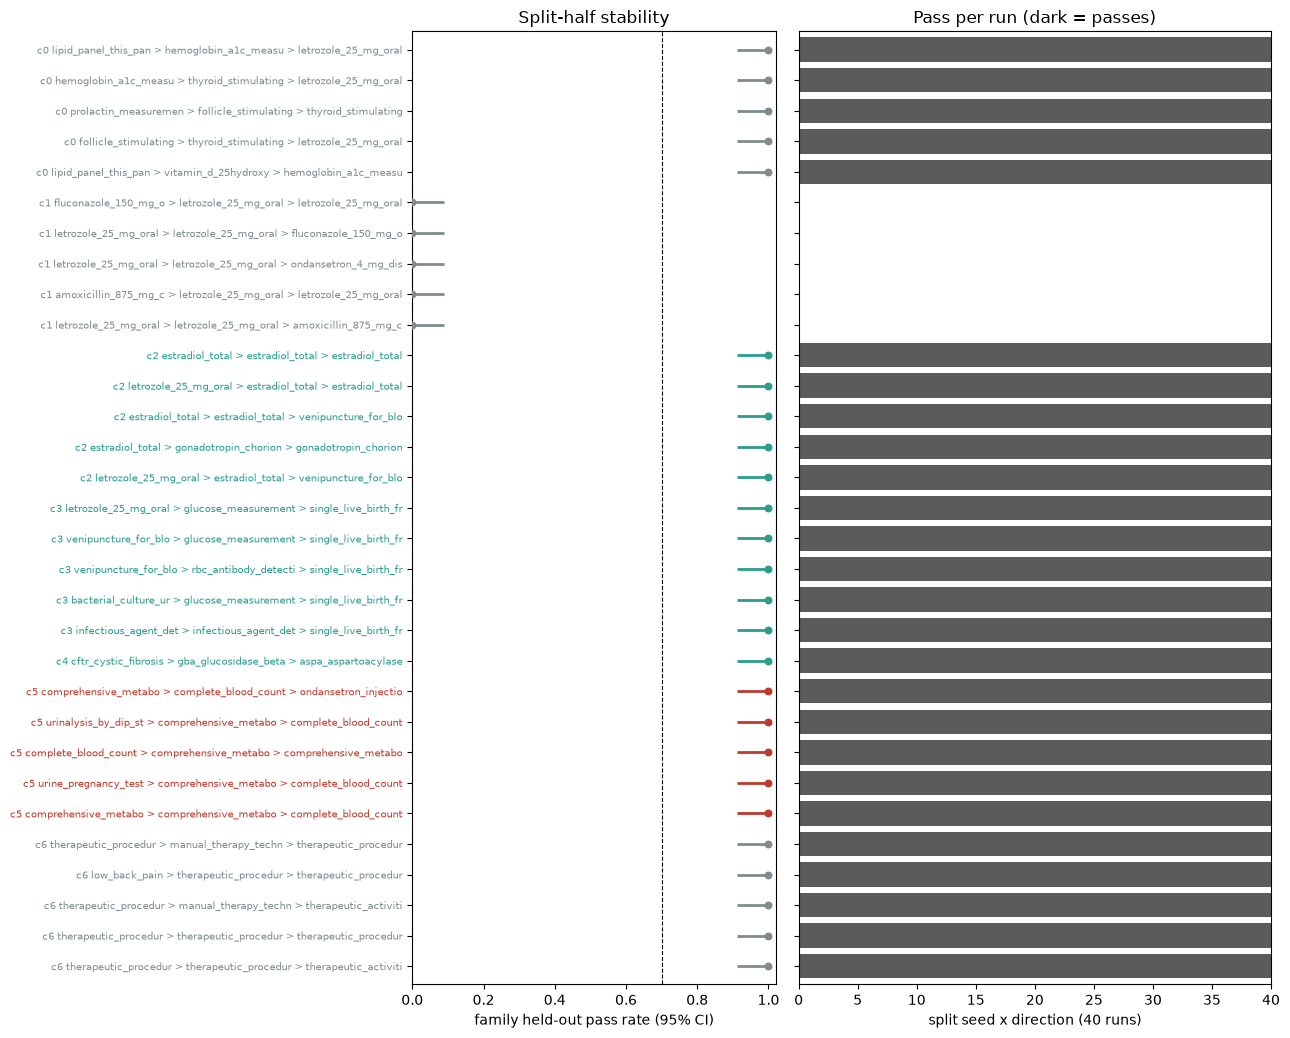

In [37]:
TOP_N = 5
GC = {FERT: '#2A9D8F', ONCO: '#C0392B', BG: '#7F8C8D'}
short = lambda pat: ' > '.join(t.split('__')[0] for t in pat.split(' -> '))   # drop vocabulary / concept-id suffix
sel = []
for c, (_, name, grp, _) in COMP.items():
    d = rows[c]
    if len(d):
        for i in np.flatnonzero(d.is_family_rep.to_numpy())[:TOP_N]:
            sel.append((c, i, grp, f"c{c} {short(d.pattern.iloc[i])}"))
y = np.arange(len(sel))[::-1]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 0.28 * len(sel) + 1.8), sharey=True, gridspec_kw={'width_ratios': [1, 1.3]})
for yy, (c, i, grp, lab) in zip(y, sel):
    d = rows[c].iloc[i]
    ax.hlines(yy, d.fam_holdout_rate_lo, d.fam_holdout_rate_hi, color=GC[grp], lw=2)
    ax.scatter(d.fam_holdout_rate, yy, color=GC[grp], s=22, zorder=3)
    ax2.imshow(ho_runs[c][i][None, :].astype(float), extent=(0, 40, yy - .4, yy + .4), aspect='auto', cmap='Greys', vmin=0, vmax=1.4)
ax.axvline(HO_MIN_RATE_LO, ls='--', c='k', lw=.8); ax.set_xlim(0, 1.02)
ax.set_xlabel('family held-out pass rate (95% CI)'); ax.set_yticks(y); ax.set_yticklabels([s[3] for s in sel], fontsize=7)
for t, s in zip(ax.get_yticklabels(), sel): t.set_color(GC[s[2]])
ax2.set_xlim(0, 40); ax2.set_ylim(-.6, len(sel) - .4); ax2.set_xlabel('split seed x direction (40 runs)')
ax.set_title('Split-half stability'); ax2.set_title('Pass per run (dark = passes)')
plt.tight_layout(); plt.show()

How to read the table:

- **`lift_lo` / `lift_hi`** is the bootstrap 95% range. A narrow range far above `MIN_LIFT` means the number is
  steady. A range that dips toward 1 means the motif is only as specific as the particular patients drawn.
- **`splits_found`** counts the seeds (out of 5) where the motif was nominated on the train half and held up on the
  held-out half. 5/5 is a motif that does not depend on which patients were drawn.
- Small components (c4, n=269; c5, n=406) have 135-203 patients per half, so their splits are the noisiest. Treat
  a c5 verdict more cautiously than a c2 one.
- **What this does not test.** The component labels come from the full-data NMF, so this is stability *given* those
  labels (Day 1 v2 already showed them solid, bootstrap ARI 0.876). And the top motifs inside a component are often
  variants of each other (same codes, one extra step); stability does not merge them, so one real pathway can fill
  several rows.
- Only motifs reaching `rel_sup` in-component are tested at all. A true but rare motif never becomes a candidate.

### Conservative vs exploratory run — the knobs side by side

"Conservative" = fewer motifs, each one harder to dismiss as chance. "Exploratory" = more motifs, rarer ones,
more of them noise. The middle column is the original default. **Currently set in this notebook:** `rel_sup` 0.15, `max_cand` 100, bootstrap `B` 1,000; everything else is still the default. Change the value where it is defined, then re-run
from that cell down.

| Knob | Where | Exploratory | **Original default** | Conservative | What it does |
|---|---|---|---|---|---|
| `rel_sup` / `REL_SUP` | mining cell (`component_motifs(rel_sup=...)`) **and** 2b cell 1 | 0.05 | **0.10** | 0.15 - 0.20 | Share of a component's patients that must contain the motif. Lower finds rarer motifs; cost grows fast. |
| `max_len` | `prefixspan(..., max_len=4)` in the mining and split cells | 5 | **4** | 3 | Longest motif. Longer = more specific stories, far fewer patients each, much slower. |
| `max_cand` / `MAX_CAND` | mining cell and 2b split cell | 60 | **60** | 100 | Only this many top-support motifs get a lift score. Larger misses fewer real motifs; it adds no false positives if the filters below are strict. |
| `n_out` / `N_OUT` | mining cell and 2b cell 1 | 1,500 | **1,500** | 3,000 | Outside patients used for `sup_out`. Larger = steadier lift denominator. |
| `MIN_LIFT` | 2b cell 1 | 1.5 | **2** | 3 | How specific to its component a motif must be to count. |
| `B` | 2b bootstrap cell | 200 | **500** | 1,000 | Bootstrap draws. Only narrows the lift range; seconds either way. |
| `SPLIT_SEEDS` | 2b split cell | (1, 2, 3) | **(1, 2, 3, 4, 5)** | (1 ... 10) | Independent 50 / 50 splits. More seeds = a more trustworthy `splits_found`. Runtime scales linearly. |
| `MIN_SPLITS_OK` | 2b verdict cell | 2 of 3 | **4 of 5** | all seeds (5 of 5, 10 of 10) | Splits a motif must replicate in to be `solid`. |
| `lift_lo >= MIN_LIFT` | 2b verdict cell | drop the condition | **kept** | kept | Whether the bootstrap range also has to clear `MIN_LIFT`. |
| probe `min_in` | probe cell (`min_in=0.10`, floor `0.08`) | 0.05 / 0.04 | **0.10 / 0.08** | 0.15 / 0.12 | Same idea as `rel_sup`, for the fertility / oncology probe. Oncology has only 59 labelled patients, so keep it low unless you accept an empty table. |
| graph edge floor | trajectory cell (`max(5, 0.02 * n)`) | 1% | **2%** | 5% | Share of patients an A -> B step needs to be drawn. |

**Runtime.** The default run took about 4.6 min for the mining cell; the slowest piece is the c1 job (1,600
patients). Exploratory settings (`rel_sup` 0.05, `max_len` 5) make that slower by an amount I have not measured.
Conservative mining (`rel_sup` 0.15, `max_len` 3) is faster, but 10 seeds doubles the split-seed cell.

**Keep these in step.** `rel_sup`, `max_cand` and `n_out` appear in the mining cell *and* in section 2b. If they
disagree, the bootstrap scores one candidate set while the splits nominate another, and the two tiers stop being
comparable.

**Reading the two modes.** Run both on the same data. A motif that is `solid` in the conservative run is safe to put
in a catalog. A motif that only appears in the exploratory run is a lead to check with Zack, not a result.

**This is the deliverable.** Ordered patterns, with in-group and out-group support, that read
as sentences. No transformer, no embeddings, no non-commercial licence to negotiate.

## 3 · Interval relations — when order is not enough

Order says "A before B." It does not say "A seven years before B" versus "A two months
before B," which is the actual letrozole discriminator. Allen's interval algebra defines 13
relations; for point events on dates, a **signed gap** carries most of the value.

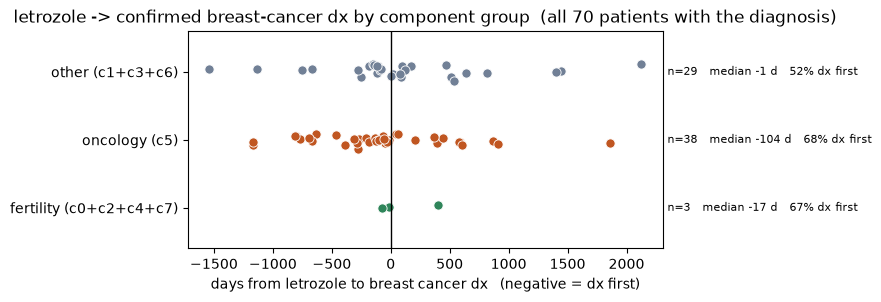

,n,mean,median,dx_first_pct
fertility (c0+c2+c4+c7),3,103.0,-17.0,67.0
oncology (c5),38,-76.0,-104.0,68.0
other (c1+c3+c6),29,100.0,-1.0,52.0


In [38]:
# One colour per component group, used by this plot and by the trajectory graph below.
# Group comes from COMP: fertility = c0+c2+c4+c7, oncology = c5, other = c1+c3+c6.
GCOL  = {FERT: '#2f855a', ONCO: '#c05621', BG: '#718096'}
GNAME = {FERT: 'fertility (c0+c2+c4+c7)', ONCO: 'oncology (c5)', BG: 'other (c1+c3+c6)'}
grp_of = pd.Series(comp, index=pids).map(lambda c: COMP[c][2] if c in COMP else np.nan)

# Confirmed breast cancer dx = ICD-10 C50.x or SNOMED 4162253 (ICD-9 174.x finds none here); `first_dx` and `lz`
# come from the mini Table 1 cell above, so the case definition lives in one place.
gaps = pd.concat([lz.rename('t_a'), first_dx.rename('t_b')], axis=1, join='inner')   # patients with letrozole AND a confirmed dx
gaps['days_a_to_b'] = (gaps.t_b - gaps.t_a).dt.days
gaps = gaps.rename_axis('person_id').reset_index()
gaps['group'] = gaps.person_id.map(grp_of)
lanes = [FERT, ONCO, BG]

rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(9.5, 3.2))
for y, g in enumerate(lanes):
    d = gaps.loc[gaps.group == g, 'days_a_to_b']
    ax.scatter(d, y + rng.normal(0, .06, len(d)), s=44, color=GCOL[g], edgecolor='white', linewidth=.6)
    ax.text(1.01, y, f"n={len(d)}   median {d.median():.0f} d   {(d < 0).mean():.0%} dx first" if len(d) else "n=0",
            transform=ax.get_yaxis_transform(), va='center', fontsize=8)
ax.axvline(0, c='k', lw=1)
ax.set_yticks(range(len(lanes))); ax.set_yticklabels([GNAME[g] for g in lanes]); ax.set_ylim(-.6, len(lanes) - .4)
ax.set_xlabel('days from letrozole to breast cancer dx   (negative = dx first)')
ax.set_title(f'letrozole -> confirmed breast-cancer dx by component group  (all {len(gaps)} patients with the diagnosis)')
fig.subplots_adjust(left=.22, right=.72, bottom=.2); plt.show()

summary = (gaps.groupby('group').days_a_to_b
               .agg(n='count', mean='mean', median='median', dx_first_pct=lambda s: (s < 0).mean() * 100)
               .round(0).reindex(lanes))
summary.index = [GNAME[g] for g in summary.index]
display(summary)

**One signed integer.** Worth remembering the next time the conversation turns to four weeks
of GPU pretraining.

**Reading the plot.** Each circle is one patient, filled by the component group they belong to
(fertility, oncology, other). Left of the black line the diagnosis was recorded *before* letrozole.
"Diagnosis" here is the **confirmed breast cancer dx** from the mini Table 1 above (ICD-10 C50.x or SNOMED 4162253;
ICD-9 174.x finds nobody in this extract), not the narrower `breast_cancer` tag. This is the **whole population** with
that diagnosis (70 in the current extract), so the count cannot be raised by sampling. Read a lane with only a handful
of patients as unreadable.

Two cautions on real data. This feature is only meaningful where lookback covers the earlier
event — otherwise you are measuring enrolment, not biology. And for patients with no cancer
diagnosis at all the feature is NULL, which is not the same as zero; carry an explicit
`no_dx_in_lookback` flag rather than imputing.

### 3b · Same question, matched comparison groups

The plot above can only contain patients **with** a confirmed diagnosis, so it has no comparison group. Here the
oncology lane is **all confirmed-dx patients** (whatever their NMF component) and the two comparison lanes are
patients with **no** confirmed dx from the fertility components (c0+c2+c4+c7) and the other components (c1+c3+c6).
Controls have no diagnosis date, so the x-axis changes to something every group can have:
**days from first letrozole to first oncology evidence** (`eo.ONCOLOGY_TAGS`: mastectomy, chemotherapy, receptor assay,
radiation, ...). Negative = the oncology evidence came first.

- Oncology evidence is rare in the controls, so each lane draws a **random sample of the same size as the oncology lane's
  plotted n** (fixed seed), taken from the patients who have it. The table keeps the true coverage in each full group,
  because sampling hides that.
- These tags are the ones that define the oncology weak label, and some sit in non-cancer patients, so read this as
  "when does cancer-type care appear around letrozole", not as a cancer test.
- c5 patients without a confirmed dx are in neither comparison lane.

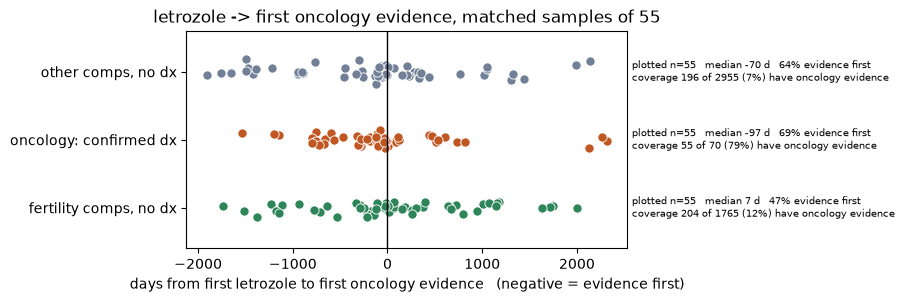

,patients in group,with oncology evidence,coverage %,plotted n,median days,p25,p75,evidence first %
lane,,,,,,,,
"fertility comps, no dx",1765,204,12.0,55,7.0,-288.0,662.0,47.0
oncology: confirmed dx,70,55,79.0,55,-97.0,-395.0,102.0,69.0
"other comps, no dx",2955,196,7.0,55,-70.0,-609.0,254.0,64.0


In [39]:
LANE_NAME = {FERT: 'fertility comps, no dx', ONCO: 'oncology: confirmed dx', BG: 'other comps, no dx'}
onc_first = events[eo.group_mask(events, eo.ONCOLOGY_TAGS)].groupby('person_id').event_date.min()
gap2      = (onc_first - lz).dt.days.dropna()                      # patients with letrozole AND oncology evidence

by_grp = lambda grp: set(grp_of.index[grp_of == grp]) - case_ids
pools  = {FERT: by_grp(FERT), ONCO: case_ids, BG: by_grp(BG)}      # comparison lanes exclude every confirmed-dx patient
have   = {k: sorted(set(gap2.index) & p) for k, p in pools.items()}
N_PLOT = len(have[ONCO])                                           # match the oncology lane's plotted n
rng    = np.random.default_rng(0)
samp   = {k: (have[k] if k == ONCO else sorted(rng.choice(have[k], min(N_PLOT, len(have[k])), replace=False)))
          for k in lanes}

fig, ax = plt.subplots(figsize=(10.5, 3.2))
for y, k in enumerate(lanes):
    d = gap2.loc[samp[k]]
    ax.scatter(d, y + rng.normal(0, .06, len(d)), s=44, color=GCOL[k], edgecolor='white', linewidth=.6)
    ax.text(1.01, y, f"plotted n={len(d)}   median {d.median():.0f} d   {(d < 0).mean():.0%} evidence first\n"
                     f"coverage {len(have[k])} of {len(pools[k])} ({len(have[k]) / len(pools[k]):.0%}) have oncology evidence",
            transform=ax.get_yaxis_transform(), va='center', fontsize=7.5)
ax.axvline(0, c='k', lw=1)
ax.set_yticks(range(len(lanes))); ax.set_yticklabels([LANE_NAME[k] for k in lanes]); ax.set_ylim(-.6, len(lanes) - .4)
ax.set_xlabel('days from first letrozole to first oncology evidence   (negative = evidence first)')
ax.set_title(f'letrozole -> first oncology evidence, matched samples of {N_PLOT}')
fig.subplots_adjust(left=.22, right=.64, bottom=.2); plt.show()

rows = []
for k in lanes:
    d = gap2.loc[samp[k]]
    rows.append({'lane': LANE_NAME[k], 'patients in group': len(pools[k]), 'with oncology evidence': len(have[k]),
                 'coverage %': round(len(have[k]) / len(pools[k]) * 100, 1), 'plotted n': len(d),
                 'median days': d.median(), 'p25': d.quantile(.25), 'p75': d.quantile(.75),
                 'evidence first %': round((d < 0).mean() * 100, 1)})
display(pd.DataFrame(rows).set_index('lane').round(0))

## 4 · Trajectory graph — the readable artifact

Aggregate consecutive transitions into a weighted directed graph. This is close to the UI
sketch from the review, but derived from observed transitions rather than a model's guess
about the next event.

In [44]:
import networkx as nx

# every curated codeset tag (codesets.yaml via eo); the raw per-product codes would swamp the graph
FOCUS = set(eo.CODESETS)

# the graph is about curated clinical steps: relabel each concept token by its group, drop uncurated ones, collapse repeats
import itertools
_tg = events.drop_duplicates('tag').dropna(subset=['groups']).set_index('tag')['groups'].astype(str).str.split('|').to_dict()   # token -> ALL its groups
gseqs = {p: [g for g, _ in itertools.groupby(g for t in seqs[p] for g in _tg.get(t, ()))] for p in pids}
Hg = eo.group_loadings(H, events)       # a group's NMF loading = sum over its concept tokens (a token counts in every group it is in)
db_lz_g = [[c for c in gseqs[p] if c in FOCUS] for p in pids if 'letrozole' in gseqs[p]]
print(f"{len(db_lz_g)} letrozole patients")

cnt = collections.Counter()
for s in db_lz_g:
    for u, v in zip(s, s[1:]):
        cnt[(u, v)] += 1
G = nx.DiGraph()
for (u, v), w in cnt.items():
    if w >= max(5, int(0.02 * len(db_lz_g))):
        G.add_edge(u, v, weight=w)
print(G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")

# Fill colour = the component group that owns the tag's NMF loading (its share of the tag's total
# loading; fertility is summed over its 4 components). letrozole is the cohort anchor, so it is not in
# the NMF; tags dropped by the prevalence floor are not in H either.
grp_comps = {g: [k for k, v in COMP.items() if v[2] == g] for g in GCOL}
def owner_group(tag):
    if tag == 'letrozole':
        return 'anchor'
    if tag not in Hg.columns or Hg[tag].sum() == 0:
        return 'not in NMF'
    share = {g: Hg.loc[ks, tag].sum() / Hg[tag].sum() for g, ks in grp_comps.items()}
    return max(share, key=share.get)
NODE_COL = {**GCOL, 'anchor': '#f6e05e', 'not in NMF': '#e2e8f0'}
node_grp = {n: owner_group(n) for n in G.nodes()}
print("nodes per group:", dict(collections.Counter(node_grp.values())))


5238 letrozole patients
17 nodes, 120 edges
nodes per group: {'oncology': 2, 'anchor': 1, 'fertility': 6, 'background': 8}


### Trajectory graph on a time axis
x = median days from the first letrozole to the first time the patient has that group (negative = before it), y = the component group that owns the tag's NMF loading. Nodes in a lane are staggered by x, so labels cannot overlap. The cell above only builds the transitions (`G`).

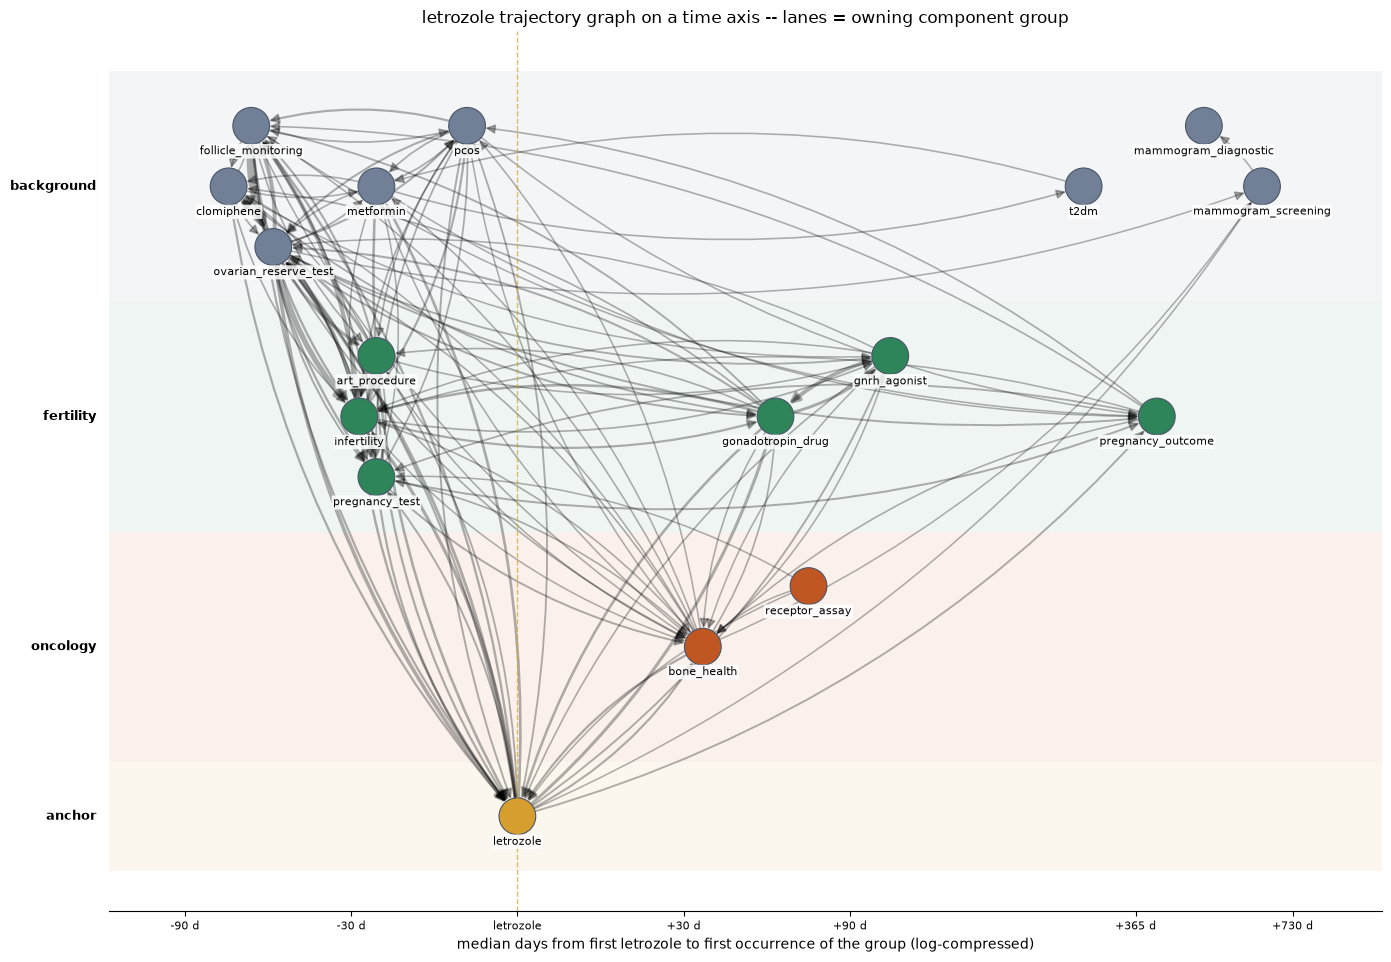

{'background': 8, 'fertility': 6, 'oncology': 2, 'anchor': 1} nodes per lane; 0 without timing


In [45]:
# Trajectory graph on a time axis: x = median days from the patient's first letrozole to the first time the patient has that group
# (log-compressed, 0 = letrozole), y = the component group that owns the tag's NMF loading. Nodes in one lane are staggered by x, so labels cannot overlap.
# Edges are the transitions in G (cell above). Needs the graph cell above and the dated sequences (patseqs) from the hybrid section.
ANCHOR      = 'letrozole'
ANCHOR_NAME = ANCHOR.replace('_', ' ')
MIN_N       = 20                                                   # fewer patients with both -> no timing, node parked at the right edge
SLOT, LABEL_IN = 1.0, 1.15                                          # vertical stagger step (y units), room one label needs on the x axis (inches)

_nodes  = set(G.nodes())
_have   = [i for i, p in enumerate(pids) if ANCHOR in gseqs[p]]     # the cohort of the graph
_first  = {n: [] for n in _nodes}
_a_tok  = {t for t, gs in _tg.items() if ANCHOR in gs}
for i in _have:
    ps = patseqs[i]
    a0 = min((ps.dpos[t][0] for t in _a_tok if t in ps.dpos), default=None)
    if a0 is None:
        continue
    best = {}
    for t, dl in ps.dpos.items():
        for g in _tg.get(t, ()):
            if g in _nodes and (g not in best or dl[0] < best[g]):
                best[g] = dl[0]
    for g, d in best.items():
        _first[g].append(d - a0)
med = {g: float(np.median(v)) for g, v in _first.items() if len(v) >= MIN_N}
med[ANCHOR] = 0.0

Hg_    = Hg if 'Hg' in globals() else eo.group_loadings(H, events)
comps_ = list(dict.fromkeys(v[2] for v in COMP.values()))           # component groups, in COMP order
def owner_lane(g):
    if g == ANCHOR:
        return 'anchor'
    if g not in Hg_.columns or Hg_[g].sum() == 0:
        return 'not in NMF'
    share = {l: Hg_.loc[[k for k, v in COMP.items() if v[2] == l], g].sum() / Hg_[g].sum() for l in comps_}
    return max(share, key=share.get)
lane_of  = {n: owner_lane(n) for n in _nodes}
LANES    = [l for l in comps_ + ['anchor', 'not in NMF'] if l in set(lane_of.values())]
_pal     = ['#2f855a', '#c05621', '#718096', '#2b6cb0', '#b83280', '#b7791f']
LANE_COL = {**{l: _pal[i % len(_pal)] for i, l in enumerate(comps_)}, 'anchor': '#d69e2e', 'not in NMF': '#a0aec0', **globals().get('GCOL', {})}

tf = lambda d: np.sign(d) * np.log1p(np.abs(d) / 30)                # days -> compressed axis, 0 stays 0
xs = {g: tf(m) for g, m in med.items() if g in _nodes}
x_park = (max(xs.values()) if xs else 0) + 1.4
_all_x = list(xs.values()) + ([x_park] if any(n not in xs for n in _nodes) else [])
MIN_DX = LABEL_IN * (max(_all_x) - min(_all_x) + 1) / 12.0           # x units that fit one label on a 14 in wide figure
order  = [0] + [s * k for k in range(1, 13) for s in (1, -1)]
slot_of, lane_k = {}, {}
for l in LANES:
    members = sorted((n for n in _nodes if lane_of[n] == l), key=lambda n: (xs.get(n, x_park), n))
    last = {}                                                      # slot -> x of the last node placed there
    for n in members:
        x = xs.get(n, x_park)
        k = next(k for k in order if x - last.get(k, -1e9) >= MIN_DX)
        last[k] = x; slot_of[n] = (l, k, x)
    lane_k[l] = max((abs(k) for (ll, k, _) in slot_of.values() if ll == l), default=0)
heights = {l: 2 * lane_k[l] * SLOT + 1.8 for l in LANES}            # a lane is as tall as its stagger needs
centers, y_top = {}, 0.0
for l in LANES:
    centers[l] = y_top - heights[l] / 2; y_top -= heights[l]
pos_t = {n: (x, centers[l] + k * SLOT) for n, (l, k, x) in slot_of.items()}

fig, ax = plt.subplots(figsize=(14, max(5, 0.6 * (-y_top) + 1.8)))
for l in LANES:
    ax.axhspan(centers[l] - heights[l] / 2, centers[l] + heights[l] / 2, color=LANE_COL.get(l, '#e2e8f0'), alpha=.08, lw=0)
    ax.text(-0.01, centers[l], l, transform=ax.get_yaxis_transform(), ha='right', va='center', fontsize=9, fontweight='bold')
w = np.array([G[u][v]['weight'] for u, v in G.edges()], dtype=float)
nx.draw_networkx_edges(G, pos_t, ax=ax, width=1 + 4 * w / w.max(), alpha=.3, arrowsize=14, node_size=700, connectionstyle='arc3,rad=0.15')
nx.draw_networkx_nodes(G, pos_t, ax=ax, node_size=700, node_color=[LANE_COL.get(lane_of[n], '#e2e8f0') for n in G.nodes()], edgecolors='#4a5568', linewidths=.8)
nx.draw_networkx_labels(G, {n: (x, y - 0.42) for n, (x, y) in pos_t.items()}, ax=ax, font_size=8,
                        bbox=dict(boxstyle='round,pad=0.12', fc='white', ec='none', alpha=.85))
ax.tick_params(axis='x', bottom=True, labelbottom=True)              # networkx hides the ticks
tick_d = [-365, -90, -30, 0, 30, 90, 365, 730]
ax.set_xticks([tf(d) for d in tick_d]); ax.set_xticklabels([f"{d:+d} d" if d else ANCHOR_NAME for d in tick_d], fontsize=8)
ax.axvline(0, color='#d69e2e', lw=1, ls='--', alpha=.7)
if any(n not in xs for n in _nodes):
    ax.text(x_park, 0.3, f'timing n<{MIN_N}', ha='center', fontsize=8, color='#718096')
ax.set_yticks([]); ax.spines[['left', 'right', 'top']].set_visible(False)
ax.set_xlabel(f"median days from first {ANCHOR_NAME} to first occurrence of the group (log-compressed)")
ax.set_title(f'{ANCHOR_NAME} trajectory graph on a time axis -- lanes = owning component group')
plt.margins(x=.06); plt.tight_layout(); plt.show()
print({l: int(sum(1 for n in _nodes if lane_of[n] == l)) for l in LANES}, "nodes per lane;", sum(1 for n in _nodes if n not in xs), "without timing")


Read the arms against the NMF components: a fertility-treatment arm (clomiphene,
gonadotropins, ART), a pregnancy arm (pregnancy test, pregnancy outcome), and a much thinner
oncology arm (receptor assay, biopsy, chemotherapy, mastectomy). Whichever dominates numerically
is the answer — let the graph say which, rather than assuming.

**How to read it.** Left to right is time: each tag sits at the median number of days between the patient's first letrozole and the first time they have that tag (log-compressed; left = before letrozole, right = after, the dashed line is letrozole). Each row (lane) is the component group that owns most of the tag's NMF loading (fertility, oncology or other, as grouped in `COMP`). `letrozole` has its own lane because it is the cohort anchor and not in the NMF; a tag too rare to reach the NMF goes to a "not in NMF" lane. Tags inside a lane are staggered up and down only so the labels do not overlap: the vertical offset has no meaning. A tag with fewer than 20 patients who have both it and letrozole has no timing and is parked at the right edge. Positions use the *first* occurrence, so a tag that repeats (labs, drugs) can look earlier than the cycle next to letrozole. A lane is a loading share, not a diagnosis, and a tag shared between groups takes the larger share. Arrows are the observed transitions between consecutive curated steps; thicker = more patients.


## 5 · Final table — one per experiment (Excel)
One row per ordered pattern, grouped by NMF bundle in order c0, c1, ... The bundle's size and top-5 OMOP entities come from the NMF loaded from the Day 1 v3 cache. UW suggestion, supported literature (drop-down) and PMIDs are left empty for the review; supported literature and PMIDs are the last two columns. Written next to this notebook; needs `openpyxl`.

In [42]:
COHORT = 'letrozole'
# ONE condensed final table per experiment: bundles in NMF order (c0, c1, ...), each with its top-5 OMOP entities and its top-TOPK ordered patterns.
# Uses the NMF loaded above (cache from Day1_nmf_v3), not a refit. The literature / PMID / pathway / UW columns are left for the review.
import re, itertools, collections
try:
    import openpyxl
except ImportError as e:
    raise ImportError("pip install openpyxl in this kernel's environment, then rerun this cell") from e
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter
from openpyxl.worksheet.datavalidation import DataValidation

TOPK, TOP_ENT = 3, 5            # patterns per bundle (highest lift first) / entities per bundle
RANK_BY = 'loading'             # entities ranked by NMF loading ('loading') or by share of the bundle's patients having the code ('prevalence')
XLSX_FINAL = f"Day3_v3_concept_final_table_{COHORT}_k{K}.xlsx"
cdx = concept.drop_duplicates('concept_id').set_index('concept_id')

def _condense_name(n, limit=38):
    s = re.split(r' \(|;| This ', n)[0].strip()
    s = s if len(s) >= 8 else n                                      # packs like '{6 (azithromycin ...) } Pack' would be cut to '{6'
    return s if len(s) <= limit else s[:limit].rsplit(' ', 1)[0] + '…'

def label(token):
    m = re.search(r'__(\d+)$', token)
    if m and int(m.group(1)) in cdx.index:
        r = cdx.loc[int(m.group(1))]
        return f"{_condense_name(r.concept_name)} [{r.vocabulary_id} {r.concept_code}]"
    return f"{token.replace('_', ' ')} [code group]"

def pattern_text(pattern):
    parts = []
    for t, g in itertools.groupby(pattern.split(' -> ')):
        n = len(list(g)); parts.append(label(t) + (f" ×{n}" if n > 1 else ""))
    return ' → '.join(parts)

HEAD = ['Group (bundle)', 'n (%)', 'Most frequently OMOP clinical entities found', 'Rank (by lift)', 'Typical order of care (condensed names, vocabulary + code)', 'Share of group with pattern', 'Share of everyone else with pattern', 'Re-tests found (of 5)', 'Holds up on re-test?', 'Times as common (lift)', 'Final verdict', 'Triage suggestion', 'Order shown by dates?', 'Supported literature (Yes / Partly / None)', 'PMIDs']
BUNDLE_COLS = (1, 2, 3, 12)                   # merged down the rows of a bundle

table = []                                                          # list of (bundle number, row values)
for c in sorted(COMP):
    members = np.flatnonzero(comp == c)
    cnt   = collections.Counter(t for i in members for t in set(db[i]))
    share = lambda t: cnt.get(t, 0) / max(len(members), 1)
    score = H.iloc[c] if RANK_BY == 'loading' else pd.Series({t: share(t) for t in H.columns})
    ents  = "\n".join(f"{i}. {label(t)} ({share(t):.0%} of bundle)" for i, t in enumerate(score.nlargest(TOP_ENT).index, 1))
    head  = [f"c{c} · {COMP[c][1]}", f"{len(members):,} ({len(members) / len(comp):.1%})", ents]
    d = hyb[c].head(TOPK) if len(hyb.get(c, [])) else hyb[c].iloc[0:0] if c in hyb else None
    if d is None or not len(d):
        table.append((c, head + [''] * (len(HEAD) - 3)))
        continue
    for rk, (_, r) in enumerate(d.iterrows(), 1):
        holds = 'Yes' if r.splits_found >= 4 else 'Partly' if r.splits_found == 3 else 'No'
        row = (head if rk == 1 else ['', '', '']) + [rk, pattern_text(r.pattern), float(r.sup_in), float(r.sup_out), int(r.splits_found), holds,
                                                     float(r.lift), r.hybrid_verdict.capitalize(), '', 'Same-day bundle' if r.same_day_bundle else 'Yes', '', '']
        table.append((c, row))

FILL = {'Yes': 'D6F0DE', 'Partly': 'FBEFC9', 'No': 'F8D7D7', 'Solid': 'D6F0DE', 'Suggestive': 'FBEFC9', 'Unstable': 'F8D7D7', 'Same-day bundle': 'FBEFC9'}
F = lambda **kw: Font(name='Arial', size=10, **kw)
thin = Side(style='thin', color='D0D5DB')
wb = openpyxl.Workbook(); ws = wb.active; ws.title = f'{COHORT} k={K}'
ws.append(HEAD)
for j in range(1, len(HEAD) + 1):
    h = ws.cell(1, j); h.font = Font(name='Arial', size=10, bold=True, color='FFFFFF')
    h.fill = PatternFill('solid', fgColor='334E68'); h.alignment = Alignment(wrap_text=True, vertical='center', horizontal='center')
ws.row_dimensions[1].height = 44
for _, row in table:
    ws.append(row)
dv = DataValidation(type='list', formula1='"Yes,Partly,None"', allow_blank=True); ws.add_data_validation(dv)
LEFT = {1, 3, 5, 12}
for i in range(2, len(table) + 2):
    ws.row_dimensions[i].height = 64
    for j in range(1, len(HEAD) + 1):
        c_ = ws.cell(i, j); c_.font = F(bold=(j == 1)); c_.border = Border(bottom=thin)
        c_.alignment = Alignment(wrap_text=True, vertical='top', horizontal='left' if j in LEFT else 'center')
    for j in (6, 7): ws.cell(i, j).number_format = '0.0%'
    ws.cell(i, 10).number_format = '0.0'
    for j in (9, 11, 13):
        v = ws.cell(i, j).value
        if v in FILL: ws.cell(i, j).fill = PatternFill('solid', fgColor=FILL[v]); ws.cell(i, j).font = F(bold=True)
    dv.add(ws.cell(i, 14))
r0 = 2
for c, grp in itertools.groupby([b for b, _ in table]):               # one merged block per bundle
    n = len(list(grp)); r1 = r0 + n - 1
    if n > 1:
        for j in BUNDLE_COLS: ws.merge_cells(start_row=r0, end_row=r1, start_column=j, end_column=j)
    r0 = r1 + 1
for j, w in enumerate([30, 14, 70, 8, 80, 12, 13, 11, 11, 11, 12, 34, 14, 16, 16], 1):
    ws.column_dimensions[get_column_letter(j)].width = w
ws.freeze_panes = 'B2'
notes = [
    "Notes",
    f"Source: Day 3 v3 concept, letrozole run, NMF k={K} on concept-level tokens (Day 1 v3, loaded from cache), {len(db):,} patients. Bundles are the NMF components in order c0, c1, ...; n (%) = patients whose dominant component is the bundle.",
    f"Entities: the top {TOP_ENT} OMOP concepts of the bundle ranked by {'NMF loading' if RANK_BY == 'loading' else 'share of the bundle patients having the code'}; the % is the share of the bundle's patients with that code.",
    f"Patterns: the {TOPK} highest-lift ordered patterns of each bundle, taken from its most common ordered patterns of 3+ steps (each present in >={REL_SUP:.0%} of the bundle). Several are variants of one pathway.",
    "Times as common = (share inside bundle + 0.01) / (share outside + 0.01). Outside = random sample of 1,500 patients from other bundles.",
    "Re-tests: each bundle split in half at random, 5 times; patterns found on one half and checked on the other. Yes = found in 4-5 of 5, Partly = 3, No = 0-2.",
    f"Final verdict = the hybrid verdict: Solid = re-found in >=4 of 5 re-tests with lift range low >= {MIN_LIFT}, downgraded to Suggestive when the family held-out pass rate lower bound is below {HO_MIN_RATE_LO:.0%} ({len(HO_SEEDS)} splits x 2 directions); Suggestive = found in 3 of 5; Unstable otherwise.",
    f"Order shown by dates? 'Same-day bundle' = with every step required on a strictly later day, support falls below {SAME_DAY_RATIO:.0%} of its table value: the steps mostly occur together on one day, so the order is a tie-break, not evidence.",
    "Triage suggestion, Supported literature (Yes / Partly / None, drop-down) and PMIDs are left empty for the review.",
    "'×N' = the same concept appears N times in a row. '[code group]' = a curated group of several codes.",
]
for k_, t in enumerate(notes):
    ws.cell(len(table) + 3 + k_, 1, t).font = F(bold=(k_ == 0))
wb.save(XLSX_FINAL)
print(f"wrote {os.path.abspath(XLSX_FINAL)}  ({len(COMP)} bundles, {len(table)} rows)")
pd.DataFrame([r for _, r in table], columns=HEAD).iloc[:, :11]


wrote /Users/esteban.correaagudelo/codeprojects/ethos_foundation_llm/nb/repr_learn_letrozole/Day3_v3_concept_final_table_letrozole_k7.xlsx  (7 bundles, 21 rows)


,Group (bundle),n (%),Most frequently OMOP clinical entities found,Rank (by lift),"Typical order of care (condensed names, vocabulary + code)",Share of group with pattern,Share of everyone else with pattern,Re-tests found (of 5),Holds up on re-test?,Times as common (lift),Final verdict
0,c0 · preventive and fertility work-up labs,775 (14.8%),1. Hemoglobin A1c measurement [SNOMED 43396009...,1,Lipid panel [CPT4 80061] → Hemoglobin A1c meas...,0.440,0.121,4,Yes,3.4,Solid
1,,,,2,Hemoglobin A1c measurement [SNOMED 43396009] →...,0.467,0.139,5,Yes,3.2,Solid
2,,,,3,Prolactin measurement [SNOMED 113083009] → Fol...,0.441,0.129,2,No,3.2,Unstable
3,c1 · acute-infection and symptomatic pharmacy,"1,768 (33.8%)",1. amoxicillin 875 MG / clavulanate 125… [RxNo...,1,fluconazole 150 MG Oral Tablet [RxNorm 197699]...,0.153,0.102,0,No,1.5,Unstable
4,,,,2,letrozole 2.5 MG Oral Tablet [RxNorm 200064] ×...,0.150,0.106,0,No,1.4,Unstable
5,,,,3,letrozole 2.5 MG Oral Tablet [RxNorm 200064] ×...,0.169,0.123,0,No,1.4,Unstable
6,c2 · fertility treatment and work-up,637 (12.2%),1. estradiol 2 MG Oral Tablet [RxNorm 197659] ...,1,Estradiol [CPT4 82670] ×4,0.526,0.091,2,No,5.3,Unstable
7,,,,2,Estradiol [CPT4 82670] ×3 → Progesterone measu...,0.534,0.103,2,No,4.8,Unstable
8,,,,3,Estradiol [CPT4 82670] ×3,0.575,0.115,5,Yes,4.7,Solid
9,c3 · pregnancy and prenatal care,858 (16.4%),1. Single live birth from singleton… [SNOMED 1...,1,letrozole 2.5 MG Oral Tablet [RxNorm 200064] →...,0.550,0.070,5,Yes,7.0,Solid


## 5b · Anchor-focused view — top letrozole sequences and where they rank
Additional to the table above (which stays as is): the same bundles, but only ordered patterns that contain a letrozole step, with their rank among the bundle's scored top patterns (by lift and by support). Post-filter of the scored candidates, no re-mining, so every score and verdict is the one in the main table. Writes its own xlsx.

In [43]:
COHORT = 'letrozole'
# ANCHOR-FOCUSED view of the final table (additional; the table above is untouched): per bundle, the top-TOPK_ANCHOR scored ordered patterns that contain a letrozole step,
# with the position of that step (k of n). Same scores / verdicts as the table above (post-filter of hyb, no re-mining). Own xlsx file; Triage / literature / PMIDs left empty.
import re, itertools, collections
try:
    import openpyxl
except ImportError as e:
    raise ImportError("pip install openpyxl in this kernel's environment, then rerun this cell") from e
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter
from openpyxl.worksheet.datavalidation import DataValidation

TOPK, TOP_ENT = 3, 5            # patterns per bundle (highest lift first) / entities per bundle
RANK_BY = 'loading'             # entities ranked by NMF loading ('loading') or by share of the bundle's patients having the code ('prevalence')
XLSX_FINAL = f"Day3_v3_concept_anchor_table_{COHORT}_k{K}.xlsx"
cdx = concept.drop_duplicates('concept_id').set_index('concept_id')

ANCHOR      = 'letrozole'                                                    # cohort anchor group (codesets.yaml)
ANCHOR_NAME = ANCHOR.replace('_', ' ')
ANCHOR_TOK  = set(events.loc[eo.group_mask(events, ANCHOR), 'tag'])    # every concept-level token that belongs to the anchor group
TOPK_ANCHOR = 3                                                       # anchor patterns per bundle (highest lift first)

def has_anchor(pattern):
    return any(t in ANCHOR_TOK for t in pattern.split(' -> '))

_a0 = {}
def offset_text(c, members, t, min_n=20):
    """Median days from each patient's first {ANCHOR} step to their first occurrence of token t (negative = t came first), over the bundle's patients who have both."""
    if c not in _a0:                                                       # first anchor day per member, computed once per bundle
        _a0[c] = np.array([min((patseqs[i].dpos[x][0] for x in ANCHOR_TOK if x in patseqs[i].dpos), default=np.nan) for i in members])
    td = np.array([patseqs[i].dpos[t][0] if t in patseqs[i].dpos else np.nan for i in members])
    g  = (td - _a0[c])[~np.isnan(td - _a0[c])]
    if len(g) < min_n:
        return f"\n    vs first {ANCHOR_NAME}: too few patients with both (n={len(g)})"
    med = int(np.median(g))
    when = "same day as" if med == 0 else f"{abs(med):,} d {'before' if med < 0 else 'after'}"
    return f"\n    median {when} first {ANCHOR_NAME} ({(g < 0).mean():.0%} of them before)"

def _condense_name(n, limit=38):
    s = re.split(r' \(|;| This ', n)[0].strip()
    s = s if len(s) >= 8 else n                                      # packs like '{6 (azithromycin ...) } Pack' would be cut to '{6'
    return s if len(s) <= limit else s[:limit].rsplit(' ', 1)[0] + '…'

def label(token):
    m = re.search(r'__(\d+)$', token)
    if m and int(m.group(1)) in cdx.index:
        r = cdx.loc[int(m.group(1))]
        return f"{_condense_name(r.concept_name)} [{r.vocabulary_id} {r.concept_code}]"
    return f"{token.replace('_', ' ')} [code group]"

def pattern_text(pattern):
    parts = []
    for t, g in itertools.groupby(pattern.split(' -> ')):
        n = len(list(g)); parts.append(label(t) + (f" ×{n}" if n > 1 else ""))
    return ' → '.join(parts)

HEAD = ['Group (bundle)', 'n (%)', 'Most frequently OMOP clinical entities found', 'Rank (by lift)', 'Typical order of care (condensed names, vocabulary + code)', "Position in the bundle's scored top patterns (by lift · by support)", 'Share of group with pattern', 'Share of everyone else with pattern', 'Re-tests found (of 5)', 'Holds up on re-test?', 'Times as common (lift)', 'Final verdict', 'Triage suggestion', 'Order shown by dates?', 'Supported literature (Yes / Partly / None)', 'PMIDs']
BUNDLE_COLS = (1, 2, 3, 13)                   # merged down the rows of a bundle

table = []                                                          # list of (bundle number, row values)
for c in sorted(COMP):
    members = np.flatnonzero(comp == c)
    cnt   = collections.Counter(t for i in members for t in set(db[i]))
    share = lambda t: cnt.get(t, 0) / max(len(members), 1)
    score = H.iloc[c] if RANK_BY == 'loading' else pd.Series({t: share(t) for t in H.columns})
    ents  = "\n".join(f"{i}. {label(t)} ({share(t):.0%} of bundle){offset_text(c, members, t)}" for i, t in enumerate(score.nlargest(TOP_ENT).index, 1))
    head  = [f"c{c} · {COMP[c][1]}", f"{len(members):,} ({len(members) / len(comp):.1%})", ents]
    pool  = hyb.get(c)
    pool  = pool if pool is not None and len(pool) else None
    if pool is not None:
        pool = pool.assign(rk_lift=np.arange(1, len(pool) + 1), rk_sup=pool.sup_in.rank(ascending=False, method='min').astype(int))   # hyb[c] is lift-sorted
        has  = pool.pattern.map(has_anchor)
    d     = pool[has].head(TOPK_ANCHOR) if pool is not None else None
    head[1] += f"\n{int(has.sum()) if pool is not None else 0} of {len(pool) if pool is not None else 0} scored patterns contain {ANCHOR_NAME}"
    if d is None or not len(d):
        table.append((c, head + ['', f"no scored pattern contains {ANCHOR_NAME} (bundle has {len(pool) if pool is not None else 0} scored patterns)"] + [''] * (len(HEAD) - 5)))
        continue
    for rk, (_, r) in enumerate(d.iterrows(), 1):
        holds = 'Yes' if r.splits_found >= 4 else 'Partly' if r.splits_found == 3 else 'No'
        row = (head if rk == 1 else ['', '', '']) + [rk, pattern_text(r.pattern), f"{int(r.rk_lift)} of {len(pool)} by lift · {int(r.rk_sup)} of {len(pool)} by support", float(r.sup_in), float(r.sup_out), int(r.splits_found), holds,
                                                     float(r.lift), r.hybrid_verdict.capitalize(), '', 'Same-day bundle' if r.same_day_bundle else 'Yes', '', '']
        table.append((c, row))

FILL = {'Yes': 'D6F0DE', 'Partly': 'FBEFC9', 'No': 'F8D7D7', 'Solid': 'D6F0DE', 'Suggestive': 'FBEFC9', 'Unstable': 'F8D7D7', 'Same-day bundle': 'FBEFC9'}
F = lambda **kw: Font(name='Arial', size=10, **kw)
thin = Side(style='thin', color='D0D5DB')
wb = openpyxl.Workbook(); ws = wb.active; ws.title = f'{COHORT} k={K}'
ws.append(HEAD)
for j in range(1, len(HEAD) + 1):
    h = ws.cell(1, j); h.font = Font(name='Arial', size=10, bold=True, color='FFFFFF')
    h.fill = PatternFill('solid', fgColor='334E68'); h.alignment = Alignment(wrap_text=True, vertical='center', horizontal='center')
ws.row_dimensions[1].height = 44
for _, row in table:
    ws.append(row)
dv = DataValidation(type='list', formula1='"Yes,Partly,None"', allow_blank=True); ws.add_data_validation(dv)
LEFT = {1, 3, 5, 13}
for i in range(2, len(table) + 2):
    ws.row_dimensions[i].height = 64
    for j in range(1, len(HEAD) + 1):
        c_ = ws.cell(i, j); c_.font = F(bold=(j == 1)); c_.border = Border(bottom=thin)
        c_.alignment = Alignment(wrap_text=True, vertical='top', horizontal='left' if j in LEFT else 'center')
    for j in (7, 8): ws.cell(i, j).number_format = '0.0%'
    ws.cell(i, 11).number_format = '0.0'
    for j in (10, 12, 14):
        v = ws.cell(i, j).value
        if v in FILL: ws.cell(i, j).fill = PatternFill('solid', fgColor=FILL[v]); ws.cell(i, j).font = F(bold=True)
    dv.add(ws.cell(i, 15))
r0 = 2
for c, grp in itertools.groupby([b for b, _ in table]):               # one merged block per bundle
    n = len(list(grp)); r1 = r0 + n - 1
    if n > 1:
        for j in BUNDLE_COLS: ws.merge_cells(start_row=r0, end_row=r1, start_column=j, end_column=j)
    r0 = r1 + 1
for j, w in enumerate([30, 22, 70, 8, 80, 22, 12, 13, 11, 11, 11, 12, 34, 14, 16, 16], 1):
    ws.column_dimensions[get_column_letter(j)].width = w
ws.freeze_panes = 'B2'
notes = [
    "Notes",
    f"Source: Day 3 v3 concept, letrozole run, NMF k={K} on concept-level tokens (Day 1 v3, loaded from cache), {len(db):,} patients. Bundles are the NMF components in order c0, c1, ...; n (%) = patients whose dominant component is the bundle.",
    f"Entities: the top {TOP_ENT} OMOP concepts of the bundle ranked by {'NMF loading' if RANK_BY == 'loading' else 'share of the bundle patients having the code'}; the % is the share of the bundle's patients with that code.",
    f"Patterns: the {TOPK_ANCHOR} highest-lift scored ordered patterns of each bundle that contain a {ANCHOR_NAME} step (any {ANCHOR_NAME} concept), from the same candidates as the main table (ordered patterns of 3+ steps, each present in >={REL_SUP:.0%} of the bundle). The second line of each n (%) cell says how many of the bundle's scored patterns contain {ANCHOR_NAME}.",
    f"Entities: under each entity, the median number of days from the patient's first {ANCHOR_NAME} step to their FIRST occurrence of that entity (before / after), over the bundle patients who have both, and the share of them for whom it came first. Repeated entities (labs, drugs) are read at their first occurrence.",
    "Position among the bundle's scored top patterns: each bundle's candidates are its 100 most frequent ordered patterns (3+ steps) that pass the support floor, scored for lift; the pattern's place in that list by lift (1 = most specific to the bundle) and by support (1 = most frequent), out of the N patterns scored. A bundle with no such pattern is shown as such, not filled.",
    "Times as common = (share inside bundle + 0.01) / (share outside + 0.01). Outside = random sample of 1,500 patients from other bundles.",
    "Re-tests: each bundle split in half at random, 5 times; patterns found on one half and checked on the other. Yes = found in 4-5 of 5, Partly = 3, No = 0-2.",
    f"Final verdict = the hybrid verdict: Solid = re-found in >=4 of 5 re-tests with lift range low >= {MIN_LIFT}, downgraded to Suggestive when the family held-out pass rate lower bound is below {HO_MIN_RATE_LO:.0%} ({len(HO_SEEDS)} splits x 2 directions); Suggestive = found in 3 of 5; Unstable otherwise.",
    f"Order shown by dates? 'Same-day bundle' = with every step required on a strictly later day, support falls below {SAME_DAY_RATIO:.0%} of its table value: the steps mostly occur together on one day, so the order is a tie-break, not evidence.",
    "Triage suggestion, Supported literature (Yes / Partly / None, drop-down) and PMIDs are left empty for the review.",
    "'×N' = the same concept appears N times in a row. '[code group]' = a curated group of several codes.",
]
for k_, t in enumerate(notes):
    ws.cell(len(table) + 3 + k_, 1, t).font = F(bold=(k_ == 0))
wb.save(XLSX_FINAL)
print(f"wrote {os.path.abspath(XLSX_FINAL)}  ({len(COMP)} bundles, {len(table)} rows)")
pd.DataFrame([r for _, r in table], columns=HEAD).iloc[:, :12]


wrote /Users/esteban.correaagudelo/codeprojects/ethos_foundation_llm/nb/repr_learn_letrozole/Day3_v3_concept_anchor_table_letrozole_k7.xlsx  (7 bundles, 19 rows)


,Group (bundle),n (%),Most frequently OMOP clinical entities found,Rank (by lift),"Typical order of care (condensed names, vocabulary + code)",Position in the bundle's scored top patterns (by lift · by support),Share of group with pattern,Share of everyone else with pattern,Re-tests found (of 5),Holds up on re-test?,Times as common (lift),Final verdict
0,c0 · preventive and fertility work-up labs,775 (14.8%)\n21 of 100 scored patterns contain...,1. Hemoglobin A1c measurement [SNOMED 43396009...,1,Lipid panel [CPT4 80061] → Hemoglobin A1c meas...,1 of 100 by lift · 79 of 100 by support,0.44,0.121,4,Yes,3.4,Solid
1,,,,2,Hemoglobin A1c measurement [SNOMED 43396009] →...,2 of 100 by lift · 41 of 100 by support,0.467,0.139,5,Yes,3.2,Solid
2,,,,3,Follicle stimulating hormone… [SNOMED 31003009...,4 of 100 by lift · 60 of 100 by support,0.453,0.141,5,Yes,3.1,Solid
3,c1 · acute-infection and symptomatic pharmacy,"1,768 (33.8%)\n23 of 24 scored patterns contai...",1. amoxicillin 875 MG / clavulanate 125… [RxNo...,1,fluconazole 150 MG Oral Tablet [RxNorm 197699]...,1 of 24 by lift · 22 of 24 by support,0.153,0.102,0,No,1.5,Unstable
4,,,,2,letrozole 2.5 MG Oral Tablet [RxNorm 200064] ×...,2 of 24 by lift · 24 of 24 by support,0.15,0.106,0,No,1.4,Unstable
5,,,,3,letrozole 2.5 MG Oral Tablet [RxNorm 200064] ×...,3 of 24 by lift · 13 of 24 by support,0.169,0.123,0,No,1.4,Unstable
6,c2 · fertility treatment and work-up,637 (12.2%)\n15 of 100 scored patterns contain...,1. estradiol 2 MG Oral Tablet [RxNorm 197659] ...,1,letrozole 2.5 MG Oral Tablet [RxNorm 200064] →...,7 of 100 by lift · 45 of 100 by support,0.553,0.115,5,Yes,4.5,Solid
7,,,,2,letrozole 2.5 MG Oral Tablet [RxNorm 200064] →...,20 of 100 by lift · 33 of 100 by support,0.56,0.135,5,Yes,3.9,Solid
8,,,,3,letrozole 2.5 MG Oral Tablet [RxNorm 200064] →...,34 of 100 by lift · 13 of 100 by support,0.582,0.16,5,Yes,3.5,Solid
9,c3 · pregnancy and prenatal care,858 (16.4%)\n28 of 100 scored patterns contain...,1. Single live birth from singleton… [SNOMED 1...,1,letrozole 2.5 MG Oral Tablet [RxNorm 200064] →...,1 of 100 by lift · 31 of 100 by support,0.55,0.07,5,Yes,7.0,Solid


## 6 · Export — token map
One row per token. At concept level a token **is** one OMOP concept, so this is the join table for later pipelines: `token` → `concept_id`, vocabulary, code, name, domain, every codeset it belongs to (`groups`), event / patient counts, whether it is in the NMF and which component owns it, and in how many motifs it appears. Written next to this notebook.

In [ ]:
# token map: one row per token (= one OMOP concept at concept level) so later pipelines can join on concept_id instead of parsing names
TOKEN_MAP = f"token_map_letrozole_concept.csv"
assert events.groupby('tag').concept_id.nunique().eq(1).all(), "a token maps to more than one concept_id"
first = events.drop_duplicates('tag').set_index('tag')
cnt   = events.groupby('tag').person_id.agg(n_events='size', n_patients='nunique')
keep  = [c for c in ('concept_id', 'concept_name', 'vocabulary_id', 'concept_code', 'concept_class_id', 'domain') if c in first.columns]
tm    = first[keep].join(cnt)
tm['groups']      = first['groups'].astype(str).where(first['groups'].notna(), '')            # every codeset the concept is in, '|'-joined
tm['in_nmf']      = tm.index.isin(H.columns)
tm['nmf_owner']   = H.idxmax(axis=0).reindex(tm.index).astype('Int64')                        # component with the largest loading (blank = not in the NMF)
tm['owner_share'] = (H.max(axis=0) / H.sum(axis=0)).reindex(tm.index).round(3)
_in_motifs = collections.Counter(t for d in hyb.values() if len(d) for p in d.pattern for t in set(p.split(' -> ')))
tm['n_motifs']    = tm.index.map(lambda t: _in_motifs.get(t, 0))
tm = tm.rename_axis('token').reset_index().sort_values(['n_patients', 'token'], ascending=[False, True])
tm.to_csv(TOKEN_MAP, index=False)
print(f"wrote {os.path.abspath(TOKEN_MAP)}: {len(tm):,} tokens | {int(tm.in_nmf.sum()):,} in the NMF | {int((tm.n_motifs > 0).sum()):,} appear in a motif | {int((tm.groups != '').sum()):,} belong to a codeset")
tm.head(8)